# Correlação do zero

**Um número de −1 a +1: a média dos produtos das oscilações típicas, por que ela nunca passa de 1, o mercado escondido que move os dois ativos, quanto dado ela pede, o risco da carteira meio a meio e a correlação de verdade na B3, no dólar e na crise de 2020**

Gabriel Pires · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026

---

Dois ativos oscilam 20 % ao ano cada um. Com metade do dinheiro em cada, a carteira oscila **19,0 %, 14,1 % ou 10,0 %**, conforme a correlação entre eles seja +0,80, 0 ou −0,50. O vídeo mostra o que é esse número em 16 linhas de Python. Este notebook reproduz cada número dele e vai além:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`correlacao.py`), linha por linha, e um `assert` para cada número do vídeo |
| 1 | A média dos produtos, eqs. (1) e (2): os dias 1 e 146 e os quadrantes |
| 2 | Por que nunca passa de ±1, eq. (3) |
| 3 | De onde vem o 0,80: o mercado escondido, eq. (4); correlação não é causa |
| 4 | Quanto dado a correlação pede, eqs. (5) e (6): a média corrida e o erro de Fisher |
| 5 | O risco da mistura meio a meio, eqs. (7) e (8): 19,0 %, 14,1 % e 10,0 % |
| 6 | Zero não é independência: $y = x^2$ e os dias de pânico |
| 7 | 🇧🇷 Na B3: Petrobras ON × PN, Itaú × Bradesco, Petrobras × Vale, Ibovespa × dólar |
| 8 | 🇧🇷 O erro da correlação: Fisher × bootstrap em blocos |
| 9 | 🇧🇷 As 38 ações: quanto da correlação é o mercado |
| 10 | 🇧🇷 Replicação: Forbes e Rigobon (2002) na crise de 2020, eqs. (9) e (10) |
| 11 | 🏦 Mesa: hedge de variância mínima de R\$ 1 milhão em Itaú, eq. (11) |
| 12 | 💰 Investidor: meio Ibovespa, meio dólar, ano a ano desde 1999 |
| 13 | O que a correlação não vê + exercícios |

**Dados:** as seções 0 a 6 usam a simulação do vídeo (semente 10, 10 mil anos de dias úteis). As seções 7 a 12 usam dados **reais e públicos**, todos em `dados/`: preços ajustados de PETR3, PETR4, ITUB4, BBDC4, VALE3 e BOVA11 (Yahoo Finance, 02/01/2015 a 16/10/2026); as 38 ações do vídeo da diversificação (02/01/2015 a 09/10/2026); o Ibovespa (`^BVSP`, Yahoo Finance) e o dólar PTAX de venda (Banco Central, SGS 1), de 1999 a 16/10/2026.

> O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 16 linhas que aparecem digitadas no vídeo. Dois ativos, A e B, recebem todo dia um empurrão do mesmo mercado escondido `m` e um empurrão próprio (`e` para A, `f` para B). O `c` escolhe quanto de cada um vem do mercado. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
rng = np.random.default_rng(10)
n, v = 10000 * 252, np.sqrt(252)   # 10.000 anos
s = 0.2 / v                        # 20 % ao ano
m = rng.normal(0, s, n)             # mercado escondido
e, f = rng.normal(0, s, (2, n))    # empurrões próprios
for c in (1, 0.8, 0, -0.5, -1):    # cinco pares
    k = abs(c) ** 0.5                # parte do mercado
    j = (1 - abs(c)) ** 0.5          # parte própria
    a = k * m + j * e                # ativo A
    b = np.sign(c) * k * m + j * f   # ativo B
    za = (a - a.mean()) / a.std()    # A em oscilações
    zb = (b - b.mean()) / b.std()    # B em oscilações
    r = (za * zb).mean()             # correlação
    mistura = (a + b) / 2             # metade em cada
    print(f'{r:+.2f} {mistura.std() * v:6.1%}')

+1.00  20.0%


+0.80  19.0%


+0.00  14.1%


-0.50  10.0%


-1.00   0.0%


### Bibliotecas e estilo dos gráficos

In [2]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

NAVY, BLUE, LIGHT, AMBER, RED, GREEN, GREY = "#1B2A4A", "#1E56B8", "#8FB0EA", "#F2B544", "#B42318", "#1B7A4A", "#6B7590"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "R$ 1 ... R$ 2" é dinheiro, não fórmula
})
br = lambda x, d=2: f"{round(x, d) + 0.0:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
sg = lambda x, d=2: ("+" if round(x, d) >= 0 else "") + br(x, d)                                                        # +0,80 e −0,50
pct = lambda x, d=1: br(100 * x, d) + " %"
spct = lambda x, d=1: ("+" if round(100 * x, d) >= 0 else "") + pct(x, d)                                               # +52,3 %
brl = lambda x, d=0: ("−" if x < 0 else "") + "R$ " + br(abs(x), d)
F = lambda fn, *a: (lambda x: fn(x, *a))                                                                                  # formatador de tabela
fmt = dict(decimal=",", thousands=".")
VIRG = plt.FuncFormatter(lambda x, _: f"{x:g}".replace("-", "−").replace(".", ","))                                       # eixos com vírgula

def virgula(*axs, x=True, y=True):
    for ax in axs:
        if x: ax.xaxis.set_major_formatter(VIRG)
        if y: ax.yaxis.set_major_formatter(VIRG)

### Os números do vídeo, um por um

A função `par(c)` repete as linhas 8 a 13 da tela para um valor de `c`, para conferir cada número que aparece ou é falado.

In [3]:
def par(c):
    # as linhas 8 a 13 da tela: os ativos A e B e as suas oscilações típicas
    k = abs(c) ** 0.5
    j = (1 - abs(c)) ** 0.5
    a = k * m + j * e
    b = np.sign(c) * k * m + j * f
    return a, b, (a - a.mean()) / a.std(), (b - b.mean()) / b.std()

tela = {}
for c in (1, 0.8, 0, -0.5, -1):
    a, b, za, zb = par(c)
    tela[c] = {"correlação": (za * zb).mean(), "A sozinho": a.std() * v, "B sozinho": b.std() * v, "mistura 50/50": ((a + b) / 2).std() * v}
tela = pd.DataFrame(tela).T
tela.index.name = "c"
display(tela.style.format({"correlação": F(sg), "A sozinho": F(pct), "B sozinho": F(pct), "mistura 50/50": F(pct)})
        .format_index(F(sg, 1)).set_caption("correlacao.py imprime: cada ativo sozinho 20 %; a mistura, 20,0 / 19,0 / 14,1 / 10,0 / 0,0 %"))
assert [round(x, 2) for x in tela["correlação"]] == [1.0, 0.8, 0.0, -0.5, -1.0]
assert [round(100 * x, 1) for x in tela["mistura 50/50"]] == [20.0, 19.0, 14.1, 10.0, 0.0]
assert all(round(100 * x, 1) == 20.0 for x in pd.concat([tela["A sozinho"], tela["B sozinho"]]))

a, b, za, zb = par(0.8)                # o par do vídeo
k, j = 0.8 ** 0.5, 0.2 ** 0.5
prod = za * zb                          # o produto de cada dia
corridas = {anos: prod[: anos * 252].mean() for anos in (1, 10, 100, 1000, 10000)}
print(f"{br(n / 252, 0)} anos de {252} dias úteis; empurrão do mercado × {br(k, 3)}, próprio × {br(j, 3)}: o próprio tem {br(j / k)} do tamanho")
print(f"dia 1:   {sg(za[0])} × {sg(zb[0])} = {sg(prod[0])}")
print(f"dia 146: {sg(za[145])} × {sg(zb[145])} = {sg(prod[145])}")
for anos, x in corridas.items():
    print(f"média dos produtos em {br(anos, 0):>6} anos: {br(x)}")
assert n == 10000 * 252 and round(j / k, 2) == 0.5
assert [round(za[0], 2), round(zb[0], 2), round(prod[0], 2)] == [-1.60, -1.63, 2.60]
assert [round(za[145], 2), round(zb[145], 2), round(prod[145], 2)] == [0.65, -0.66, -0.43]
assert [round(corridas[t], 2) for t in (1, 10, 100, 1000, 10000)] == [0.72, 0.80, 0.81, 0.80, 0.80]

,correlação,A sozinho,B sozinho,mistura 50/50
c,,,,
"+1,0","+1,00","20,0 %","20,0 %","20,0 %"
"+0,8","+0,80","20,0 %","20,0 %","19,0 %"
"+0,0","+0,00","20,0 %","20,0 %","14,1 %"
"−0,5","−0,50","20,0 %","20,0 %","10,0 %"
"−1,0","−1,00","20,0 %","20,0 %","0,0 %"


10.000 anos de 252 dias úteis; empurrão do mercado × 0,894, próprio × 0,447: o próprio tem 0,50 do tamanho
dia 1:   −1,60 × −1,63 = +2,60
dia 146: +0,65 × −0,66 = −0,43
média dos produtos em      1 anos: 0,72
média dos produtos em     10 anos: 0,80
média dos produtos em    100 anos: 0,81
média dos produtos em  1.000 anos: 0,80
média dos produtos em 10.000 anos: 0,80


## 1. A média dos produtos — eqs. (1) e (2)

O programa não mede os movimentos em por cento. Mede em **oscilações típicas**: quanto o dia se afastou da média, dividido pelo desvio-padrão (o *z-score*). Depois multiplica os dois movimentos de cada dia e tira a média:

$$
z_{A,t} = \frac{A_t - \bar A}{\sigma_A}, \qquad \rho = \frac{1}{n}\sum_{t=1}^{n} z_{A,t}\, z_{B,t} \tag{1}
$$

Num dia em que os dois sobem mais que o normal, ou os dois caem, o produto é positivo; num dia em que vão para lados opostos, negativo. Abrindo os *z-scores*, a média dos produtos é a covariância dividida pelos dois desvios-padrão, a definição de Pearson (1895):

$$
\rho = \frac{\frac{1}{n}\sum_t (A_t-\bar A)(B_t-\bar B)}{\sigma_A\,\sigma_B} = \frac{\mathrm{Cov}(A,B)}{\sigma_A\,\sigma_B} \tag{2}
$$

Dividir pelos desvios tira a escala: a correlação não muda se A for medido em reais ou em por cento, nem se um dos ativos for dez vezes mais volátil.

média dos produtos, eq. (1): 0,8003  |  Cov/(σσ), eq. (2) (np.corrcoef): 0,8003
A medido 1.000 vezes maior e somado de 3: 0,8003


dias com produto positivo: 79,5 %; eles somam 0,827, os negativos −0,027
para dados normais, a fração de dias com o mesmo sinal é 1/2 + arcsen(ρ)/π = 79,5 %


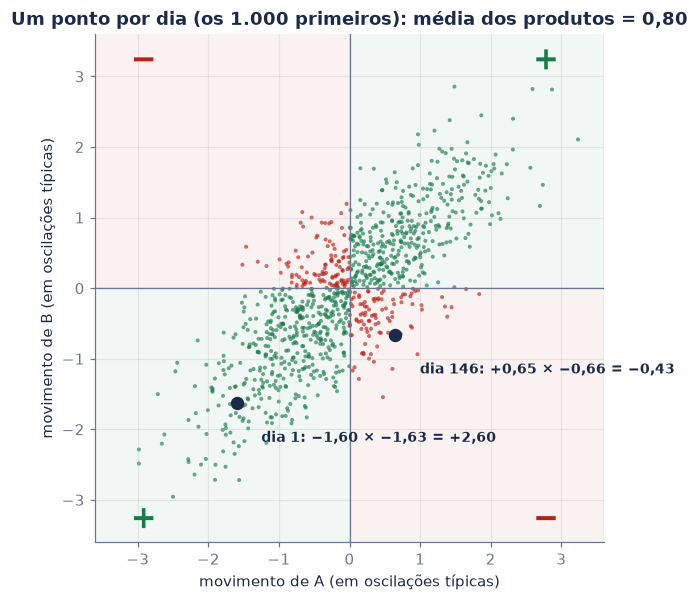

In [4]:
print(f"média dos produtos, eq. (1): {br(prod.mean(), 4)}  |  Cov/(σσ), eq. (2) (np.corrcoef): {br(np.corrcoef(a, b)[0, 1], 4)}")
print(f"A medido 1.000 vezes maior e somado de 3: {br(np.corrcoef(1000 * a + 3, b)[0, 1], 4)}")
pos = prod > 0
print(f"dias com produto positivo: {pct(pos.mean())}; eles somam {br(prod[pos].sum() / n, 3)}, os negativos {br(prod[~pos].sum() / n, 3)}")
print(f"para dados normais, a fração de dias com o mesmo sinal é 1/2 + arcsen(ρ)/π = {pct(0.5 + math.asin(0.8) / math.pi)}")
assert np.isclose(prod.mean(), np.corrcoef(a, b)[0, 1]) and np.isclose(np.corrcoef(1000 * a + 3, b)[0, 1], prod.mean())

fig, ax = plt.subplots(figsize=(6.4, 6.0))
d1k = slice(0, 1000)
ax.axhspan(0, 6, xmin=0.5, xmax=1, color=GREEN, alpha=0.06); ax.axhspan(-6, 0, xmin=0, xmax=0.5, color=GREEN, alpha=0.06)
ax.axhspan(0, 6, xmin=0, xmax=0.5, color=RED, alpha=0.06); ax.axhspan(-6, 0, xmin=0.5, xmax=1, color=RED, alpha=0.06)
cor = np.where(prod[d1k] > 0, GREEN, RED)
ax.scatter(za[d1k], zb[d1k], s=7, c=cor, alpha=0.65, lw=0)
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
for t, txt_ in ((0, "dia 1"), (145, "dia 146")):
    ax.scatter([za[t]], [zb[t]], s=60, color=NAVY, zorder=3)
    ax.annotate(f"{txt_}: {sg(za[t])} × {sg(zb[t])} = {sg(prod[t])}", (za[t], zb[t]), (za[t] + 0.35, zb[t] - 0.55), color=NAVY, weight="bold", fontsize=9)
for x_, y_, t_ in ((2.6, 3.1, "+"), (-3.1, -3.4, "+"), (-3.1, 3.1, "−"), (2.6, -3.4, "−")):
    ax.text(x_, y_, t_, fontsize=20, color=GREEN if t_ == "+" else RED, weight="bold")
ax.set(xlim=(-3.6, 3.6), ylim=(-3.6, 3.6), xlabel="movimento de A (em oscilações típicas)", ylabel="movimento de B (em oscilações típicas)",
       title=f"Um ponto por dia (os 1.000 primeiros): média dos produtos = {br(prod.mean())}")
ax.set_aspect("equal"); plt.show()

**Leitura.** Quatro em cada cinco dias caem nos quadrantes verdes (os dois do mesmo lado). Os dias vermelhos puxam a média para baixo, mas são menos e menores. O dia 1 foi um dia de queda forte para os dois: produto +2,60. O dia 146 teve A um pouco acima e B um pouco abaixo do normal: produto −0,43. A correlação é o saldo de 2,52 milhões de dias assim.

## 2. Por que nunca passa de ±1 — eq. (3)

Como cada *z-score* tem média 0 e média dos quadrados 1, abrir o quadrado dá:

$$
\frac{1}{n}\sum_t \big(z_{A,t} - z_{B,t}\big)^2 = 2\,(1-\rho) \;\ge\; 0, \qquad \frac{1}{n}\sum_t \big(z_{A,t} + z_{B,t}\big)^2 = 2\,(1+\rho) \;\ge\; 0 \tag{3}
$$

Uma média de quadrados nunca é negativa, logo $-1 \le \rho \le 1$. E $\rho = 1$ só acontece se $z_A = z_B$ em **todos** os dias: os pontos numa linha que sobe. É a desigualdade de Cauchy–Schwarz, escrita em oscilações típicas.

In [5]:
for c in (1, 0.8, 0, -0.5, -1):
    _, _, za_, zb_ = par(c)
    r_ = (za_ * zb_).mean()
    print(f"c = {sg(c, 1)}: média de (zA − zB)² = {br(((za_ - zb_) ** 2).mean(), 4)} = 2(1 − ρ) = {br(2 * (1 - r_), 4)}   |   "
          f"média de (zA + zB)² = {br(((za_ + zb_) ** 2).mean(), 4)} = 2(1 + ρ) = {br(2 * (1 + r_), 4)}")
    assert np.isclose(((za_ - zb_) ** 2).mean(), 2 * (1 - r_)) and np.isclose(((za_ + zb_) ** 2).mean(), 2 * (1 + r_))
del za_, zb_
print(f"\ncomo ângulo entre as duas séries (nota técnica): correlação 0,8 = cosseno de {br(math.degrees(math.acos(0.8)), 1)} graus; correlação 0 = 90 graus")

c = +1,0: média de (zA − zB)² = 0,0000 = 2(1 − ρ) = 0,0000   |   média de (zA + zB)² = 4,0000 = 2(1 + ρ) = 4,0000


c = +0,8: média de (zA − zB)² = 0,3994 = 2(1 − ρ) = 0,3994   |   média de (zA + zB)² = 3,6006 = 2(1 + ρ) = 3,6006


c = +0,0: média de (zA − zB)² = 1,9983 = 2(1 − ρ) = 1,9983   |   média de (zA + zB)² = 2,0017 = 2(1 + ρ) = 2,0017


c = −0,5: média de (zA − zB)² = 2,9990 = 2(1 − ρ) = 2,9990   |   média de (zA + zB)² = 1,0010 = 2(1 + ρ) = 1,0010


c = −1,0: média de (zA − zB)² = 4,0000 = 2(1 − ρ) = 4,0000   |   média de (zA + zB)² = 0,0000 = 2(1 + ρ) = 0,0000

como ângulo entre as duas séries (nota técnica): correlação 0,8 = cosseno de 36,9 graus; correlação 0 = 90 graus


## 3. De onde vem o 0,80: o mercado escondido — eq. (4)

No programa, $A = k\,M + j\,e$ e $B = \pm k\,M + j\,f$, com $M$, $e$ e $f$ independentes. Em geral, num **modelo de um fator**, $A = \beta_A M + e_A$ e $B = \beta_B M + e_B$, com os empurrões próprios independentes entre si e do mercado; então $\mathrm{Cov}(A,B) = \beta_A\beta_B\,\sigma_M^2$ e

$$
\rho_{AB} = \frac{\beta_A\,\beta_B\,\sigma_M^2}{\sigma_A\,\sigma_B} \tag{4}
$$

No vídeo, $\beta_A = k$, $\beta_B = \mathrm{sinal}(c)\,k$ e os três desvios são iguais a $s$, então $\rho = \mathrm{sinal}(c)\,k^2 = c$: o programa **escolhe** a correlação ao escolher quanto de cada empurrão vem do mercado. Com $c = 0{,}8$, $k = 0{,}894$ e $j = 0{,}447$: o empurrão próprio tem metade do tamanho do empurrão do mercado.

A correlação nunca diz qual causa o outro. Aqui nenhum causa: tire o mercado dos dois e o que sobra não tem relação nenhuma.

In [6]:
beta_a, beta_b = np.cov(a, m)[0, 1] / m.var(ddof=1), np.cov(b, m)[0, 1] / m.var(ddof=1)
print(f"betas estimados: A {br(beta_a, 3)}, B {br(beta_b, 3)} (teoria: k = {br(k, 3)})")
print(f"eq. (4): {br(beta_a * beta_b * m.var() / (a.std() * b.std()), 4)}  |  medida: {br(prod.mean(), 4)}")
sobra_a, sobra_b = a - beta_a * m, b - beta_b * m
print(f"correlação de A e B depois de tirar o mercado dos dois: {sg(np.corrcoef(sobra_a, sobra_b)[0, 1], 4)}")
assert abs(np.corrcoef(sobra_a, sobra_b)[0, 1]) < 0.005
del sobra_a, sobra_b

betas estimados: A 0,894, B 0,895 (teoria: k = 0,894)
eq. (4): 0,8001  |  medida: 0,8003
correlação de A e B depois de tirar o mercado dos dois: +0,0009


**Leitura.** Duas ações de bancos sobem e caem juntas porque respondem à mesma Selic, ao mesmo ciclo de crédito e ao mesmo humor do estrangeiro, não porque uma empurre a outra. Na seção 9, a B3 mostra isso: tirando o Ibovespa, a correlação média entre 38 ações quase some.

## 4. Quanto dado a correlação pede — eqs. (5) e (6)

No vídeo, a média corrida dos produtos passa por **0,72 em 1 ano**, 0,80 em 10, 0,81 em 100 e 0,80 em 1.000. Por que um ano erra tanto? Cada produto $z_A z_B$ é um número ruidoso: com dados normais, a variância de cada produto é $1+\rho^2$. Já a correlação **amostral** de um ano, que mede as oscilações típicas com o desvio do próprio ano, é bem mais precisa (a demonstração está na nota técnica):

$$
\mathrm{EP}\Big[\tfrac{1}{n}\textstyle\sum_t z_{A,t} z_{B,t}\Big] = \sqrt{\dfrac{1+\rho^2}{n}}, \qquad \mathrm{EP}[\hat\rho] \approx \dfrac{1-\rho^2}{\sqrt{n}} \tag{5}
$$

Com $\rho = 0{,}8$ e $n = 252$ dias: 0,081 contra 0,023. A distribuição de $\hat\rho$ é torta perto de ±1; Fisher (1915) achou a transformação que a endireita:

$$
z = \mathrm{atanh}\,\hat\rho = \frac{1}{2}\ln\frac{1+\hat\rho}{1-\hat\rho} \;\approx\; \mathcal{N}\!\left(\mathrm{atanh}\,\rho,\; \frac{1}{n-3}\right) \tag{6}
$$

Os 10 mil anos simulados conferem as duas fórmulas: dá para calcular a correlação de cada ano separadamente.

,média dos produtos (vídeo),correlação amostral do ano
média dos 10 mil anos,"0,8003","0,7997"
desvio entre os anos,"0,0808","0,0230"
eq. (5),"0,0807","0,0227"


ano 1: média dos produtos 0,72 (abaixo dela, 16 % dos anos); correlação amostral 0,77
intervalo de 95 % de Fisher (6) para o ano 1: 0,71 a 0,82; nos 10 mil anos, o intervalo cobre o 0,80 em 94,9 % dos casos


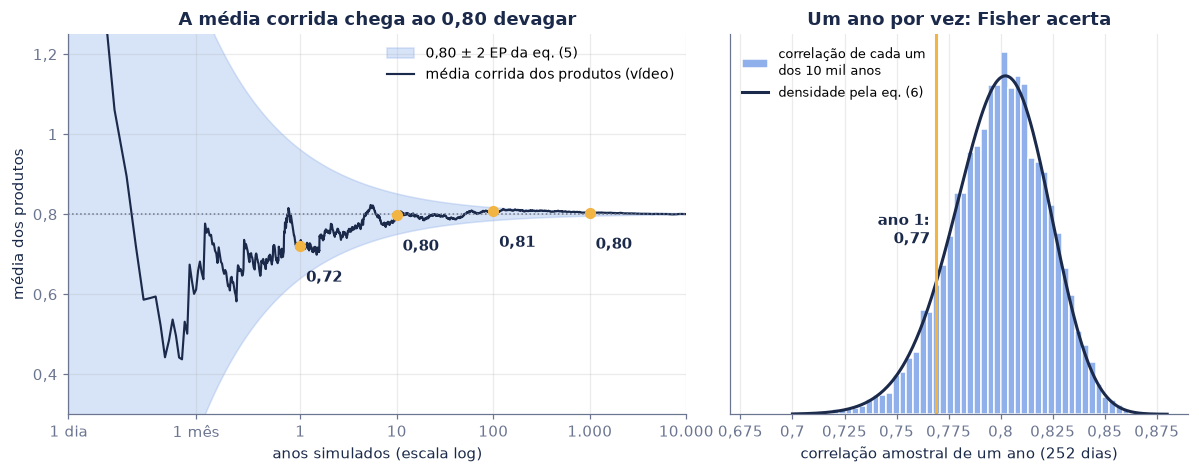

In [7]:
Ay, By = a.reshape(10000, 252), b.reshape(10000, 252)
Ay, By = Ay - Ay.mean(1, keepdims=True), By - By.mean(1, keepdims=True)
r_ano = (Ay * By).sum(1) / np.sqrt((Ay ** 2).sum(1) * (By ** 2).sum(1))     # correlação amostral de cada ano
mp_ano = prod.reshape(10000, 252).mean(1)                                    # média dos produtos de cada ano (z do vídeo)
del Ay, By
ep_prod, ep_r = math.sqrt((1 + 0.8 ** 2) / 252), (1 - 0.8 ** 2) / math.sqrt(252)
tab = pd.DataFrame({"média dos produtos (vídeo)": [mp_ano.mean(), mp_ano.std(), ep_prod], "correlação amostral do ano": [r_ano.mean(), r_ano.std(), ep_r]},
                   index=["média dos 10 mil anos", "desvio entre os anos", "eq. (5)"])
display(tab.style.format(F(br, 4)).set_caption("um ano de 252 dias, ρ verdadeiro = 0,80"))
z_ = np.arctanh(r_ano); cobre = np.abs(z_ - np.arctanh(0.8)) < 1.96 / math.sqrt(249)
lo, hi = np.tanh(np.arctanh(r_ano[0]) + np.array([-1.96, 1.96]) / math.sqrt(249))
print(f"ano 1: média dos produtos {br(mp_ano[0])} (abaixo dela, {pct((mp_ano < mp_ano[0]).mean(), 0)} dos anos); correlação amostral {br(r_ano[0])}")
print(f"intervalo de 95 % de Fisher (6) para o ano 1: {br(lo)} a {br(hi)}; nos 10 mil anos, o intervalo cobre o 0,80 em {pct(cobre.mean())} dos casos")
assert abs(mp_ano.std() / ep_prod - 1) < 0.03 and abs(r_ano.std() / ep_r - 1) < 0.05 and abs(cobre.mean() - 0.95) < 0.01

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.35, 1]})
t_ = np.unique(np.geomspace(1, n, 3000).astype(int))
corr_ = np.cumsum(prod)[t_ - 1] / t_
ax1.fill_between(t_ / 252, 0.8 - 2 * np.sqrt(1.64 / t_), 0.8 + 2 * np.sqrt(1.64 / t_), color=LIGHT, alpha=0.35, label="0,80 ± 2 EP da eq. (5)")
ax1.plot(t_ / 252, corr_, color=NAVY, lw=1.4, label="média corrida dos produtos (vídeo)")
for anos in (1, 10, 100, 1000):
    ax1.scatter([anos], [corridas[anos]], color=AMBER, zorder=3, s=40); ax1.annotate(br(corridas[anos]), (anos, corridas[anos]), (anos * 1.15, corridas[anos] - 0.09), color=NAVY, weight="bold")
ax1.axhline(0.8, color=GREY, ls=":", lw=1)
ax1.set(xscale="log", xlim=(1 / 252, 10000), ylim=(0.3, 1.25), xlabel="anos simulados (escala log)", ylabel="média dos produtos", title="A média corrida chega ao 0,80 devagar")
ax1.xaxis.set_major_locator(plt.FixedLocator([1 / 252, 1 / 12, 1, 10, 100, 1000, 10000])); ax1.xaxis.set_minor_locator(plt.NullLocator())
ax1.xaxis.set_major_formatter(plt.FixedFormatter(["1 dia", "1 mês", "1", "10", "100", "1.000", "10.000"])); virgula(ax1, x=False)
ax1.legend(frameon=False, loc="upper right", fontsize=9)
ax2.hist(r_ano, bins=60, color=LIGHT, edgecolor="white", density=True, label="correlação de cada um\ndos 10 mil anos")
xx = np.linspace(0.70, 0.88, 300)
ax2.plot(xx, np.exp(-0.5 * ((np.arctanh(xx) - np.arctanh(0.8)) * math.sqrt(249)) ** 2) * math.sqrt(249 / (2 * math.pi)) / (1 - xx ** 2), color=NAVY, lw=2, label="densidade pela eq. (6)")
ax2.axvline(r_ano[0], color=AMBER, lw=2); ax2.text(r_ano[0] - 0.003, ax2.get_ylim()[1] * 0.45, f"ano 1:\n{br(r_ano[0])}", ha="right", color=NAVY, weight="bold")
ax2.set(xlabel="correlação amostral de um ano (252 dias)", title="Um ano por vez: Fisher acerta", yticks=[]); ax2.legend(frameon=False, loc="upper left", fontsize=8.5)
virgula(ax2, y=False); plt.tight_layout(); plt.show()

**Leitura.** O 0,72 do primeiro ano do vídeo não é defeito do programa: a média dos produtos de um ano erra, tipicamente, 0,08, e 16 % dos anos simulados ficam abaixo dele. A correlação amostral do mesmo ano é 0,77, e o intervalo de Fisher em volta dela (0,71 a 0,82) contém o 0,80. Em dados simulados, independentes e normais, a eq. (6) acerta a cobertura de 95 %. Em dados de verdade, como a seção 8 mostra, ela promete precisão demais.

## 5. O risco da mistura meio a meio — eqs. (7) e (8)

A variância de uma soma tem o termo cruzado: $\mathrm{Var}\big(\tfrac{A+B}{2}\big) = \tfrac{1}{4}\big(\sigma_A^2 + \sigma_B^2 + 2\rho\,\sigma_A\sigma_B\big)$. Com $\sigma_A = \sigma_B = \sigma$:

$$
\sigma_{50/50} = \sigma\,\sqrt{\frac{1+\rho}{2}} \tag{7}
$$

A 20 % ao ano: $20\,\% \times \sqrt{0{,}9} = 19{,}0\,\%$; $\times\sqrt{0{,}5} = 14{,}1\,\%$; $\times\sqrt{0{,}25} = 10{,}0\,\%$; e zero com $\rho = -1$. Em geral, com peso $w$ em A, e com $N$ ativos de mesmo $\sigma$, pesos iguais e correlação média $\bar\rho$:

$$
\sigma_p^2 = w^2\sigma_A^2 + (1-w)^2\sigma_B^2 + 2\,w(1-w)\,\rho\,\sigma_A\sigma_B, \qquad \sigma_{1/N}^2 = \sigma^2\left[\frac{1}{N} + \Big(1-\frac{1}{N}\Big)\bar\rho\right] \tag{8}
$$

Quando $N$ cresce, sobra $\sigma\sqrt{\bar\rho}$: o piso que a diversificação não tira, e que só depende da correlação.

ρ = +1,00: eq. (7) dá 20,0 %; o programa mediu 20,0 %
ρ = +0,80: eq. (7) dá 19,0 %; o programa mediu 19,0 %
ρ = +0,00: eq. (7) dá 14,1 %; o programa mediu 14,1 %
ρ = −0,50: eq. (7) dá 10,0 %; o programa mediu 10,0 %
ρ = −1,00: eq. (7) dá 0,0 %; o programa mediu 0,0 %


,"ρ̄ = 0,00","ρ̄ = 0,35","ρ̄ = 0,80"
N = 1,"20,0 %","20,0 %","20,0 %"
N = 2,"14,1 %","16,4 %","19,0 %"
N = 5,"8,9 %","13,9 %","18,3 %"
N = 10,"6,3 %","12,9 %","18,1 %"
N = 30,"3,7 %","12,2 %","18,0 %"
N = 100,"2,0 %","11,9 %","17,9 %"
piso (N → ∞),"0,0 %","11,8 %","17,9 %"


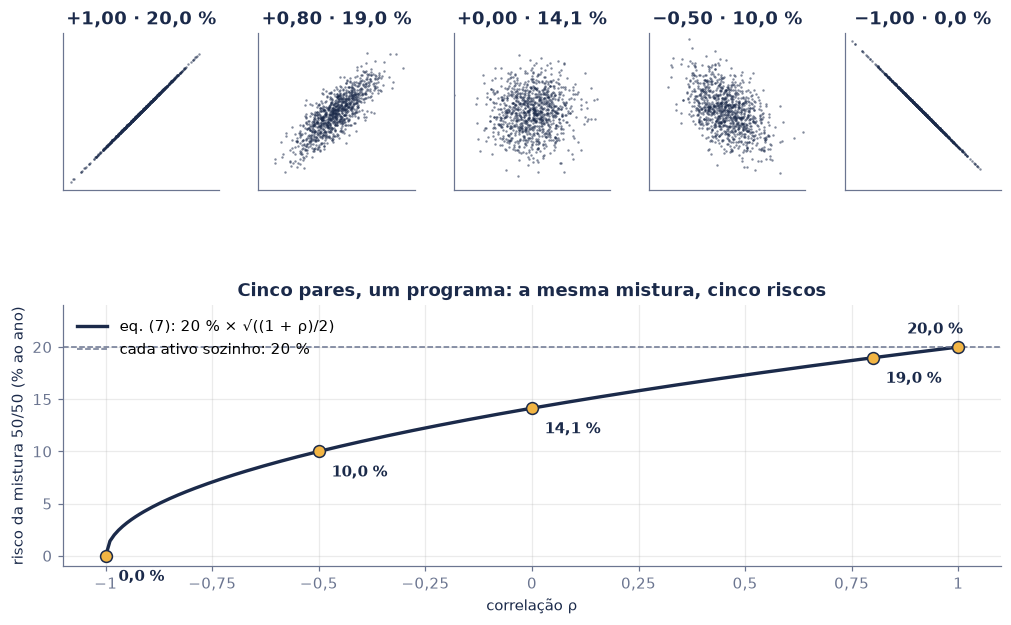

In [8]:
for c in tela.index:
    print(f"ρ = {sg(c, 2)}: eq. (7) dá {pct(0.2 * math.sqrt((1 + c) / 2))}; o programa mediu {pct(tela.loc[c, 'mistura 50/50'])}")
    assert abs(0.2 * math.sqrt((1 + c) / 2) - tela.loc[c, "mistura 50/50"]) < 0.0015
NN = [1, 2, 5, 10, 30, 100]
pisos = pd.DataFrame({f"ρ̄ = {br(rb_)}": [0.2 * math.sqrt(1 / N + (1 - 1 / N) * rb_) for N in NN] + [0.2 * math.sqrt(rb_)] for rb_ in (0, 0.35, 0.8)},
                     index=[f"N = {N}" for N in NN] + ["piso (N → ∞)"])
display(pisos.style.format(F(pct)).set_caption("eq. (8): risco de N ativos de 20 % ao ano, pesos iguais"))

fig = plt.figure(figsize=(11, 6.6)); gs = GridSpec(2, 5, height_ratios=[1, 1.25], hspace=0.38, wspace=0.25)
for i, c in enumerate(tela.index):
    ax = fig.add_subplot(gs[0, i]); _, _, za_, zb_ = par(c)
    ax.scatter(za_[:1000], zb_[:1000], s=2.5, color=NAVY, alpha=0.55, lw=0)
    ax.set(xlim=(-3.8, 3.8), ylim=(-3.8, 3.8), xticks=[], yticks=[], title=f"{sg(tela.loc[c, 'correlação'])} · {pct(tela.loc[c, 'mistura 50/50'])}"); ax.set_aspect("equal")
del za_, zb_
ax = fig.add_subplot(gs[1, :])
rr_ = np.linspace(-1, 1, 201)
ax.plot(rr_, 100 * 0.2 * np.sqrt((1 + rr_) / 2), color=NAVY, lw=2.2, label="eq. (7): 20 % × √((1 + ρ)/2)")
ax.axhline(20, color=GREY, ls="--", lw=1, label="cada ativo sozinho: 20 %")
for c in tela.index:
    y_ = 100 * tela.loc[c, "mistura 50/50"]; ax.scatter([c], [y_], s=60, color=AMBER, edgecolor=NAVY, zorder=3)
    ax.annotate(pct(tela.loc[c, "mistura 50/50"]), (c, y_), (c - 0.12, y_ + 1.3) if c == 1 else (c + 0.03, y_ - 2.4), color=NAVY, weight="bold")
ax.set(xlabel="correlação ρ", ylabel="risco da mistura 50/50 (% ao ano)", ylim=(-1, 24), title="Cinco pares, um programa: a mesma mistura, cinco riscos")
virgula(ax); ax.legend(frameon=False, loc="upper left"); plt.show()

**Leitura.** A curva é côncava: sair de +0,80 para 0 tira 4,9 pontos de risco; sair de 0 para −0,50, mais 4,1. Correlações altas mudam pouco o risco (de +1 a +0,80, só 1 ponto), e é por isso que juntar ações parecidas quase não diversifica. Com 30 ações de correlação média 0,35, a carteira ainda oscila 12,2 %: o piso de 11,8 % já está perto.

## 6. Zero não é independência

A correlação é uma média de produtos. Duas consequências que o vídeo não mostra:

1. **Ela só mede o que é linear.** Se $y = x^2$, $y$ é função exata de $x$, mas os dias de $x$ negativo cancelam os de $x$ positivo e a correlação dá zero.
2. **Poucos dias podem fazer o número.** Se dois ativos não têm relação nenhuma em 98 % dos dias, mas caem juntos nos 2 % de pânico, a correlação de todos os dias sai alta, e não diz nada sobre um dia comum.

y = x²: correlação +0,00 (de postos, +0,00), com y totalmente determinado por x
pânico: correlação com todos os dias +0,41; sem os 20 dias de pânico +0,00; de postos (Spearman) +0,05


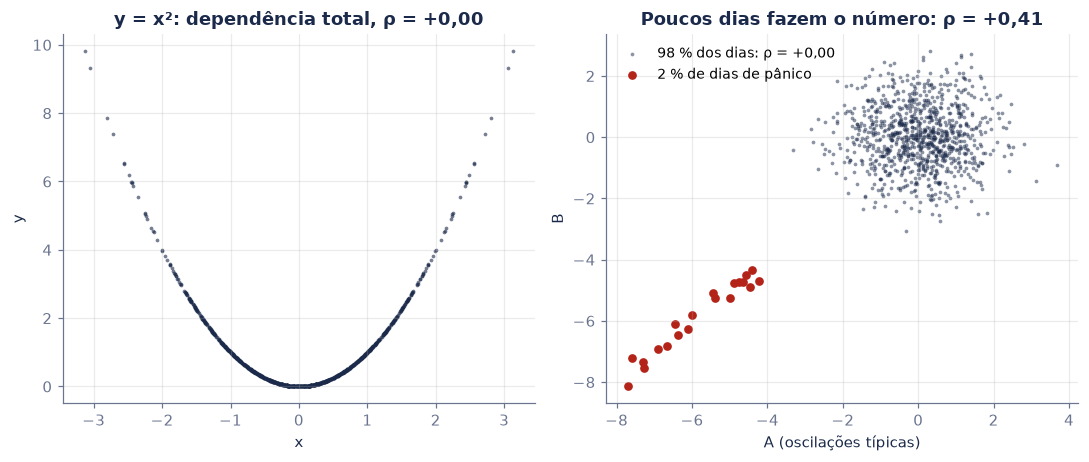

In [9]:
rng6 = np.random.default_rng(6)
x6 = rng6.normal(0, 1, 500); x6 = np.concatenate([x6, -x6]); y6 = x6 ** 2          # cada x com o seu espelho −x
p_ = rng6.normal(0, 1, (2, 1000)); panico = np.zeros(1000, bool); panico[rng6.choice(1000, 20, replace=False)] = True
queda = -rng6.uniform(4, 8, panico.sum()); p_[0, panico] = queda; p_[1, panico] = queda + rng6.normal(0, 0.3, panico.sum())
postos = lambda x: pd.Series(x).rank().values
spear = lambda x, y: np.corrcoef(postos(x), postos(y))[0, 1]
r_quad, r_pan, r_calmo = round(np.corrcoef(x6, y6)[0, 1], 12) + 0.0, np.corrcoef(*p_)[0, 1], np.corrcoef(p_[0, ~panico], p_[1, ~panico])[0, 1]
print(f"y = x²: correlação {sg(r_quad)} (de postos, {sg(spear(x6, y6))}), com y totalmente determinado por x")
print(f"pânico: correlação com todos os dias {sg(r_pan)}; sem os 20 dias de pânico {sg(r_calmo)}; de postos (Spearman) {sg(spear(*p_))}")
assert abs(r_quad) < 1e-9 and r_pan > 0.35 and abs(r_calmo) < 0.1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.3))
ax1.scatter(x6, y6, s=6, color=NAVY, alpha=0.6, lw=0); ax1.set(title=f"y = x²: dependência total, ρ = {sg(r_quad)}", xlabel="x", ylabel="y")
ax2.scatter(p_[0, ~panico], p_[1, ~panico], s=6, color=NAVY, alpha=0.5, lw=0, label=f"98 % dos dias: ρ = {sg(r_calmo)}")
ax2.scatter(p_[0, panico], p_[1, panico], s=22, color=RED, label="2 % de dias de pânico")
ax2.set(title=f"Poucos dias fazem o número: ρ = {sg(r_pan)}", xlabel="A (oscilações típicas)", ylabel="B"); ax2.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** No segundo caso, a correlação de 0,41 é verdadeira e inútil ao mesmo tempo: ela não descreve nem os dias normais (correlação zero) nem os de pânico (correlação perto de 1). A correlação de postos (Spearman), que troca cada número pela sua posição no ranking, pesa menos os extremos e fica perto de zero. Nos dados da B3, a seção 10 mostra que a crise de 2020 se parece com isso.

## 7. Na B3: pares de verdade

Agora com preços reais. Os retornos são diários e simples, de preços ajustados por proventos. Antes de calcular, três limpezas:

- dias em que o Ibovespa repete o valor da véspera ao centavo são dado parado (feriado que o Yahoo preencheu) e saem;
- os pares usam o calendário do Ibovespa, o que tira os feriados que o Yahoo preenche nas ações;
- quando falta um preço (um dia do BOVA11), o dia sai para todos, e o retorno seguinte cobre dois dias para todos.

In [10]:
ibov = pd.read_csv("dados/ibovespa.csv", index_col="data", parse_dates=True)["ibov"]
parado = ibov.diff() == 0
print("Ibovespa parado (sai):", ", ".join(ibov.index[parado].strftime("%d/%m/%Y")))
ibov = ibov[~parado]
ptax = pd.read_csv("dados/ptax.csv", index_col="data", parse_dates=True)["ptax_venda"]
pares = pd.read_csv("dados/pares_b3.csv", index_col="data", parse_dates=True)
PP = pares.join(ibov.rename("IBOV"), how="inner").join(ptax.rename("DOLAR"), how="inner").dropna()
RP = PP.pct_change().iloc[1:]
print(f"pares: {len(RP)} retornos diários, de {RP.index[0]:%d/%m/%Y} a {RP.index[-1]:%d/%m/%Y} ({len(pares) - len(PP)} linhas do Yahoo fora do calendário do Ibovespa ou sem preço)")
print("os cinco piores dias do Ibovespa na amostra:", "; ".join(f"{d:%d/%m/%Y} {pct(x)}" for d, x in RP["IBOV"].nsmallest(5).items()))

NOMES = {"PETR3": "Petrobras ON", "PETR4": "Petrobras PN", "ITUB4": "Itaú", "BBDC4": "Bradesco", "VALE3": "Vale", "BOVA11": "BOVA11", "IBOV": "Ibovespa", "DOLAR": "dólar (PTAX)"}
PARES = [("PETR3", "PETR4"), ("ITUB4", "BBDC4"), ("ITUB4", "BOVA11"), ("PETR4", "VALE3"), ("IBOV", "DOLAR"), ("VALE3", "DOLAR")]
spear = lambda x, y: x.rank().corr(y.rank())
linhas = []
for x_, y_ in PARES:
    rho_ = RP[x_].corr(RP[y_])
    mesmo = (np.sign(RP[x_]) * np.sign(RP[y_]))
    linhas.append({"par": f"{NOMES[x_]} × {NOMES[y_]}", "ρ (Pearson)": rho_, "ρ de postos (Spearman)": spear(RP[x_], RP[y_]),
                   "dias com o mesmo sinal": (mesmo > 0).sum() / (mesmo != 0).sum(), "1/2 + arcsen(ρ)/π": 0.5 + math.asin(rho_) / math.pi})
tab_pares = pd.DataFrame(linhas).set_index("par")
display(tab_pares.style.format({"ρ (Pearson)": F(sg, 3), "ρ de postos (Spearman)": F(sg, 3), "dias com o mesmo sinal": F(pct), "1/2 + arcsen(ρ)/π": F(pct)})
        .set_caption(f"retornos diários de {RP.index[0]:%d/%m/%Y} a {RP.index[-1]:%d/%m/%Y}"))

Ibovespa parado (sai): 29/10/1999, 19/11/2002, 12/08/2004, 29/09/2010, 29/12/2017
pares: 2924 retornos diários, de 05/01/2015 a 16/10/2026 (10 linhas do Yahoo fora do calendário do Ibovespa ou sem preço)
os cinco piores dias do Ibovespa na amostra: 12/03/2020 −14,8 %; 16/03/2020 −13,9 %; 09/03/2020 −12,2 %; 18/03/2020 −10,3 %; 18/05/2017 −8,8 %


,ρ (Pearson),ρ de postos (Spearman),dias com o mesmo sinal,1/2 + arcsen(ρ)/π
par,,,,
Petrobras ON × Petrobras PN,"+0,959","+0,947","91,6 %","90,9 %"
Itaú × Bradesco,"+0,829","+0,837","83,1 %","81,1 %"
Itaú × BOVA11,"+0,783","+0,766","78,7 %","78,6 %"
Petrobras PN × Vale,"+0,423","+0,350","61,5 %","63,9 %"
Ibovespa × dólar (PTAX),"−0,381","−0,315","39,1 %","37,6 %"
Vale × dólar (PTAX),"−0,133","−0,123","45,3 %","45,7 %"


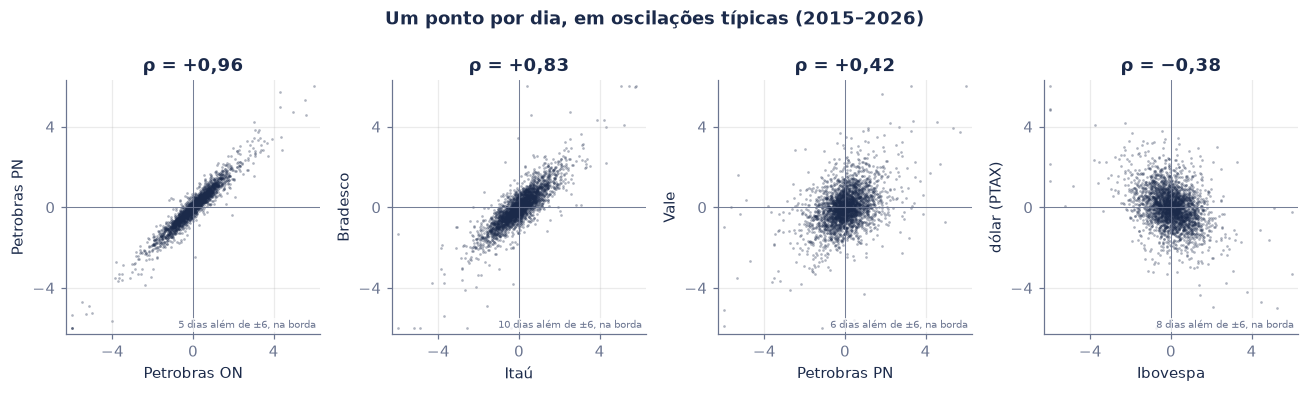

In [11]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, (x_, y_) in zip(axs, [("PETR3", "PETR4"), ("ITUB4", "BBDC4"), ("PETR4", "VALE3"), ("IBOV", "DOLAR")]):
    zx, zy = (RP[x_] - RP[x_].mean()) / RP[x_].std(), (RP[y_] - RP[y_].mean()) / RP[y_].std()
    fora = ((zx.abs() > 6) | (zy.abs() > 6)).sum()
    ax.scatter(zx.clip(-6, 6), zy.clip(-6, 6), s=3, color=NAVY, alpha=0.35, lw=0)
    ax.axhline(0, color=GREY, lw=0.6); ax.axvline(0, color=GREY, lw=0.6)
    ax.set(xlim=(-6.3, 6.3), ylim=(-6.3, 6.3), xticks=[-4, 0, 4], yticks=[-4, 0, 4], xlabel=NOMES[x_], ylabel=NOMES[y_],
           title=f"ρ = {sg(RP[x_].corr(RP[y_]))}"); ax.set_aspect("equal")
    if fora: ax.text(6.1, -6.1, f"{fora} dias além de ±6, na borda", ha="right", va="bottom", fontsize=6.5, color=GREY, bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
fig.suptitle(f"Um ponto por dia, em oscilações típicas ({RP.index[0]:%Y}–{RP.index[-1]:%Y})", color=NAVY, weight="bold"); plt.tight_layout(); plt.show()

**Leitura.** As duas ações da Petrobras são a mesma empresa com direitos diferentes: 0,96. Itaú e Bradesco dividem o mesmo negócio e o mesmo juro: 0,83. Petrobras e Vale só dividem o mercado e o ciclo das commodities: 0,42. E o dólar anda **contra** a bolsa: quando o estrangeiro sai, vende ações e compra dólar no mesmo movimento. A fração de dias com o mesmo sinal fica a no máximo 2,4 pontos da fórmula $\tfrac12 + \arcsin(\rho)/\pi$, demonstrada na nota técnica para a normal e válida para qualquer distribuição elíptica.

A correlação de um ano para o outro, porém, não fica parada:

,Petrobras ON × Petrobras PN,Itaú × Bradesco,Itaú × BOVA11,Petrobras PN × Vale,Ibovespa × dólar (PTAX),Vale × dólar (PTAX)
ano,,,,,,
2015,"+0,96","+0,88","+0,85","+0,47","−0,28","−0,07"
2016,"+0,94","+0,85","+0,80","+0,55","−0,43","−0,15"
2017,"+0,95","+0,87","+0,83","+0,35","−0,44","+0,01"
2018,"+0,96","+0,89","+0,85","+0,22","−0,37","−0,05"
2019,"+0,93","+0,82","+0,73","+0,32","−0,31","−0,12"
2020,"+0,98","+0,93","+0,83","+0,75","−0,45","−0,24"
2021,"+0,98","+0,79","+0,68","+0,30","−0,21","−0,01"
2022,"+0,96","+0,76","+0,66","+0,23","−0,47","−0,18"
2023,"+0,97","+0,77","+0,75","+0,22","−0,34","−0,22"


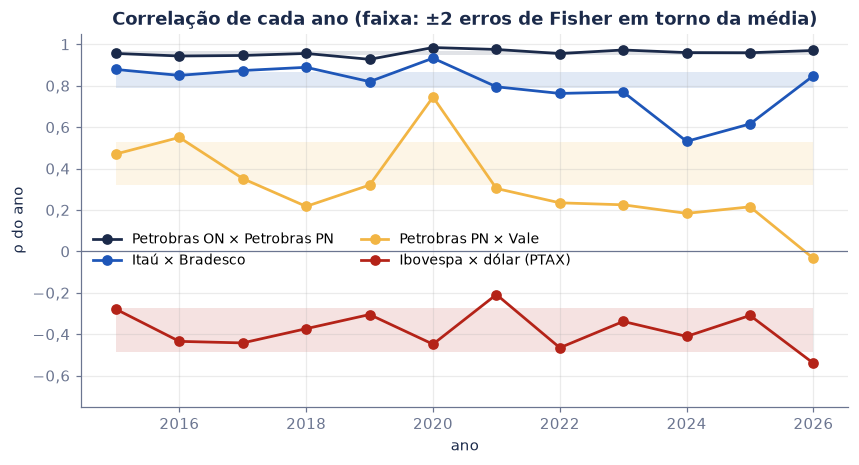

In [12]:
porano = pd.DataFrame({f"{NOMES[x_]} × {NOMES[y_]}": RP.groupby(RP.index.year).apply(lambda g: g[x_].corr(g[y_])) for x_, y_ in PARES})
porano.index.name = "ano"
display(porano.style.format(F(sg)).set_caption("correlação diária, ano a ano (2026 até 16/10)"))
fig, ax = plt.subplots(figsize=(9, 4.4))
for (x_, y_), cor in zip([("PETR3", "PETR4"), ("ITUB4", "BBDC4"), ("PETR4", "VALE3"), ("IBOV", "DOLAR")], [NAVY, BLUE, AMBER, RED]):
    nome = f"{NOMES[x_]} × {NOMES[y_]}"; r_tot = RP[x_].corr(RP[y_]); ep_ = (1 - r_tot ** 2) / math.sqrt(252)
    ax.fill_between(porano.index, r_tot - 2 * ep_, r_tot + 2 * ep_, color=cor, alpha=0.13, lw=0)
    ax.plot(porano.index, porano[nome], "o-", color=cor, lw=1.8, label=nome)
ax.axhline(0, color=GREY, lw=0.8)
ax.set(title="Correlação de cada ano (faixa: ±2 erros de Fisher em torno da média)", xlabel="ano", ylabel="ρ do ano", ylim=(-0.75, 1.05))
virgula(ax, x=False); ax.legend(frameon=False, ncol=2, fontsize=9, loc="center left", bbox_to_anchor=(0, 0.42)); plt.show()

**Leitura.** Se a correlação de Itaú e Bradesco fosse um número fixo, com 252 dias por ano ela variaria uns ±0,04 em torno de 0,83. Ela foi de 0,93 em 2020 a 0,53 em 2024: os dois bancos passaram a se mexer mais por razões próprias. Petrobras e Vale vão de 0,75 em 2020 a −0,03 em 2026. Nem o par PETR3 × PETR4, a mesma empresa, fica dentro da faixa: vai de 0,93 a 0,98. A correlação de verdade **muda**, e o erro de Fisher não sabe disso.

## 8. O erro da correlação: Fisher × bootstrap em blocos

A eq. (6) supõe dias independentes e normais. Retornos diários não são nenhuma das duas coisas: têm caudas grossas e vêm em **ondas de volatilidade** (meses calmos, meses agitados). O bootstrap estima o erro sem essas hipóteses: sorteia uma amostra nova, com reposição, recalcula a correlação e repete 2.000 vezes. O bootstrap comum sorteia dias soltos e capta as caudas; o **bootstrap em blocos** (Künsch, 1989) sorteia blocos de dias seguidos, que preservam as ondas. Abaixo, blocos de 5, 20 e 60 dias úteis.

In [13]:
def corr_boot(x, y, L=1, B=2000, seed=0):
    # correlações de B amostras bootstrap; L = 1 é o bootstrap comum, L > 1 são blocos móveis de L dias seguidos
    rng_ = np.random.default_rng(seed); nn = len(x); kk = -(-nn // L); out = []
    for _ in range(B // 500):
        ini = rng_.integers(0, nn - L + 1, (500, kk))
        idx = (ini[:, :, None] + np.arange(L)).reshape(500, -1)[:, :nn]
        xa, ya = x[idx], y[idx]
        xa, ya = xa - xa.mean(1, keepdims=True), ya - ya.mean(1, keepdims=True)
        out.append((xa * ya).sum(1) / np.sqrt((xa ** 2).sum(1) * (ya ** 2).sum(1)))
    return np.concatenate(out)

def ep_psi(x, y, L=1):
    # erro-padrão pela função de influência ψ = zA·zB − (ρ/2)(zA² + zB²); L > 1 soma as autocovariâncias com peso de Bartlett
    zx, zy = (x - x.mean()) / x.std(), (y - y.mean()) / y.std(); rho_ = (zx * zy).mean()
    psi = zx * zy - rho_ / 2 * (zx ** 2 + zy ** 2); psi = psi - psi.mean()
    var_ = (psi ** 2).mean() + 2 * sum((1 - k_ / L) * (psi[:-k_] * psi[k_:]).mean() for k_ in range(1, L))
    return math.sqrt(var_ / len(psi))

linhas = []
for i, (x_, y_) in enumerate(PARES):
    x, y = RP[x_].values, RP[y_].values; nn = len(x); rho_ = np.corrcoef(x, y)[0, 1]
    ep = {L: corr_boot(x, y, L, seed=100 + i).std(ddof=1) for L in (1, 5, 20, 60)}
    linhas.append({"par": f"{NOMES[x_]} × {NOMES[y_]}", "ρ": rho_, "Fisher (5)": (1 - rho_ ** 2) / math.sqrt(nn), "bootstrap comum": ep[1], "ψ, dias soltos": ep_psi(x, y),
                   "blocos de 5": ep[5], "blocos de 20": ep[20], "ψ, 20 dias": ep_psi(x, y, 20), "blocos de 60": ep[60], "blocos 20 / Fisher": ep[20] / ((1 - rho_ ** 2) / math.sqrt(nn)),
                   "desvio entre os anos": porano[f"{NOMES[x_]} × {NOMES[y_]}"].std(), "Fisher com 252 dias": (1 - rho_ ** 2) / math.sqrt(252)})
erros = pd.DataFrame(linhas).set_index("par")
display(erros.style.format({c_: (F(sg, 3) if c_ == "ρ" else (lambda x: br(x, 1) + "×") if c_.endswith("Fisher") and c_.startswith("blocos") else F(br, 4)) for c_ in erros.columns})
        .set_caption(f"erro-padrão da correlação diária, {len(RP)} dias (2.000 sorteios por coluna)"))
print(f"blocos de 20 dias / Fisher: de {br(erros['blocos 20 / Fisher'].min(), 1)}× a {br(erros['blocos 20 / Fisher'].max(), 1)}×")
lo_f = np.tanh(np.arctanh(erros.loc["Itaú × Bradesco", "ρ"]) + np.array([-1.96, 1.96]) / math.sqrt(len(RP) - 3))
bb = corr_boot(RP["ITUB4"].values, RP["BBDC4"].values, 20, seed=101)
print(f"Itaú × Bradesco, intervalo de 95 %: Fisher {br(lo_f[0], 3)} a {br(lo_f[1], 3)}; blocos de 20 dias {br(np.percentile(bb, 2.5), 3)} a {br(np.percentile(bb, 97.5), 3)}")
assert (erros["blocos de 20"] > 1.5 * erros["Fisher (5)"]).all()

,ρ,Fisher (5),bootstrap comum,"ψ, dias soltos",blocos de 5,blocos de 20,"ψ, 20 dias",blocos de 60,blocos 20 / Fisher,desvio entre os anos,Fisher com 252 dias
par,,,,,,,,,,,
Petrobras ON × Petrobras PN,"+0,959","0,0015","0,0032","0,0032","0,0041","0,0050","0,0051","0,0051","3,4×","0,0155","0,0050"
Itaú × Bradesco,"+0,829","0,0058","0,0157","0,0156","0,0170","0,0193","0,0196","0,0227","3,3×","0,1171","0,0197"
Itaú × BOVA11,"+0,783","0,0072","0,0119","0,0122","0,0129","0,0148","0,0146","0,0168","2,1×","0,0762","0,0244"
Petrobras PN × Vale,"+0,423","0,0152","0,0279","0,0273","0,0392","0,0495","0,0510","0,0599","3,3×","0,1998","0,0517"
Ibovespa × dólar (PTAX),"−0,381","0,0158","0,0259","0,0259","0,0283","0,0273","0,0274","0,0263","1,7×","0,0941","0,0539"
Vale × dólar (PTAX),"−0,133","0,0182","0,0243","0,0241","0,0280","0,0308","0,0313","0,0327","1,7×","0,0967","0,0619"


blocos de 20 dias / Fisher: de 1,7× a 3,4×


Itaú × Bradesco, intervalo de 95 %: Fisher 0,817 a 0,840; blocos de 20 dias 0,787 a 0,862


**Leitura.** O erro do bootstrap em blocos de 20 dias é de 1,7 a 3,4 vezes o de Fisher. Boa parte da diferença já aparece no bootstrap comum (caudas grossas: um dia de pânico pesa muito na média dos produtos); os blocos somam o efeito das ondas de volatilidade, que pesa mais em Petrobras × Vale, onde o erro quase dobra de novo. As colunas ψ fazem a mesma conta sem sorteio, pela função de influência da correlação (a nota técnica demonstra): batem com o bootstrap comum e com os blocos de 20 dias. E mesmo os blocos ficam abaixo do desvio da correlação **entre os anos**: parte da variação de um ano para o outro não é ruído de amostra, é a correlação verdadeira mudando. Regra prática: um intervalo de confiança de correlação diária calculado por Fisher é estreito demais, e com dado diário o erro-padrão sai do bootstrap em blocos.

## 9. As 38 ações: quanto da correlação é o mercado

As mesmas 38 ações do vídeo da diversificação, de 2015 a 09/10/2026. Pela eq. (4), se o Ibovespa fosse o único mercado escondido, a correlação entre duas ações seria $\beta_i\beta_j\sigma_M^2/(\sigma_i\sigma_j)$, e o que sobra depois de tirar $\beta_i M$ de cada ação (o **resíduo**) não teria correlação nenhuma. Quanto disso vale na B3?

Antes, uma limpeza. Um preço parado não é um ativo calmo: é um dia sem negócio (ou sem dado), e cada dia parado entra na média dos produtos como zero, puxando a correlação para baixo. Duas séries têm trechos longos assim: o SUZB3, cujo preço no Yahoo fica parado até 09/11/2017, e o ENGI11, que quase não negociava em 2015 e 2016. Esses trechos saem; os outros dias das duas ficam.

In [14]:
acoes = pd.read_csv("dados/acoes_b3.csv", index_col="data", parse_dates=True)
parado38 = ~(acoes.diff() != 0).any(axis=1); parado38.iloc[0] = False
print("dias com as 38 ações paradas (saem):", ", ".join(acoes.index[parado38].strftime("%d/%m/%Y")))
R38 = acoes[~parado38].join(ibov.rename("IBOV"), how="inner").pct_change().iloc[1:]
mkt = R38.pop("IBOV"); nA = R38.shape[1]; iu = np.triu_indices(nA, 1)
zeros = (R38 == 0).groupby(R38.index.year).sum()
print("dias sem variação nenhuma, por ano (as duas piores):", zeros[["SUZB3", "ENGI11"]].T.to_string())
media_crua = R38.corr().values[iu].mean()
R38.loc[:"2017-11-10", "SUZB3"] = np.nan                        # preço parado no Yahoo até 09/11/2017
R38.loc[:"2016-12-31", "ENGI11"] = np.nan                       # quase sem negócio em 2015-2016
print(f"correlação média com esses trechos (como no vídeo da diversificação): {br(media_crua, 3)}; sem eles: {br(R38.corr().values[iu].mean(), 3)}")
C38 = R38.corr().values
beta38 = R38.apply(lambda x: x.cov(mkt) / mkt[x.notna()].var())
E38 = R38 - np.outer(mkt - mkt.mean(), beta38)                  # resíduo: a ação sem o seu beta × Ibovespa
Ce = E38.corr().values
fator = np.outer(beta38, beta38) * mkt.var() / np.outer(R38.std(), R38.std())
print(f"{len(R38)} dias, {nA} ações, {len(iu[0])} pares")
print(f"correlação média entre as ações: {br(C38[iu].mean(), 3)}  |  prevista pela eq. (4) com o Ibovespa: {br(fator[iu].mean(), 3)}  |  dos resíduos: {sg(Ce[iu].mean(), 3)}")
print(f"correlação média de cada ação com o Ibovespa: {br(R38.corrwith(mkt).mean(), 3)}")
nomes_par = pd.Series(Ce[iu], index=[f"{R38.columns[i]} × {R38.columns[j]}" for i, j in zip(*iu)]).sort_values()
print("resíduos mais correlacionados:", "; ".join(f"{p_} {sg(x)}" for p_, x in nomes_par.tail(8)[::-1].items()))
print("resíduos mais negativos:", "; ".join(f"{p_} {sg(x)}" for p_, x in nomes_par.head(4).items()))
assert round(media_crua, 3) == 0.346                            # o mesmo número do vídeo da diversificação

dias com as 38 ações paradas (saem): 29/05/2017, 29/12/2017
dias sem variação nenhuma, por ano (as duas piores): data    2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
SUZB3    243   248   213     1     3     2     1     2     2     0     1     0
ENGI11   176    89    12     3     1     4     5     2     1     3     2     1
correlação média com esses trechos (como no vídeo da diversificação): 0,346; sem eles: 0,351


2920 dias, 38 ações, 703 pares
correlação média entre as ações: 0,351  |  prevista pela eq. (4) com o Ibovespa: 0,342  |  dos resíduos: +0,013
correlação média de cada ação com o Ibovespa: 0,585
resíduos mais correlacionados: BRAP4 × VALE3 +0,85; GGBR4 × GOAU4 +0,84; ITSA4 × ITUB4 +0,77; KLBN11 × SUZB3 +0,60; CSNA3 × USIM5 +0,54; BBDC4 × ITUB4 +0,53; GOAU4 × USIM5 +0,50; ENGI11 × EQTL3 +0,49
resíduos mais negativos: ITSA4 × VALE3 −0,32; MULT3 × VALE3 −0,29; CYRE3 × VALE3 −0,27; ITUB4 × VALE3 −0,27


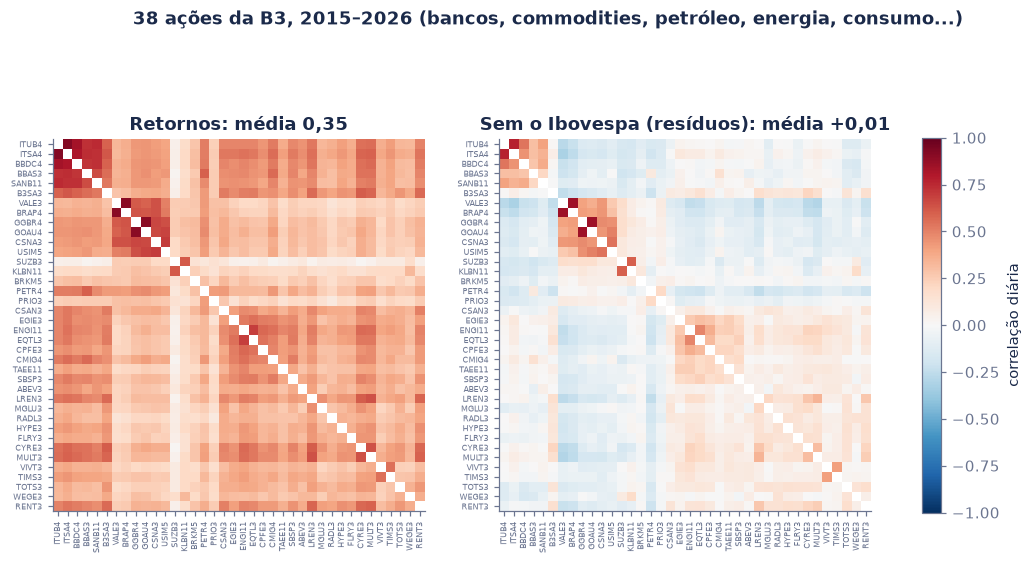

In [15]:
SETOR = ["ITUB4", "ITSA4", "BBDC4", "BBAS3", "SANB11", "B3SA3", "VALE3", "BRAP4", "GGBR4", "GOAU4", "CSNA3", "USIM5", "SUZB3", "KLBN11", "BRKM5",
         "PETR4", "PRIO3", "CSAN3", "EGIE3", "ENGI11", "EQTL3", "CPFE3", "CMIG4", "TAEE11", "SBSP3", "ABEV3", "LREN3", "MGLU3", "RADL3", "HYPE3",
         "FLRY3", "CYRE3", "MULT3", "VIVT3", "TIMS3", "TOTS3", "WEGE3", "RENT3"]
assert sorted(SETOR) == sorted(R38.columns)
ordem = [list(R38.columns).index(t) for t in SETOR]
fig, axs = plt.subplots(1, 2, figsize=(12, 5.9))
for ax, M_, tit in zip(axs, [C38, Ce], [f"Retornos: média {br(C38[iu].mean())}", f"Sem o Ibovespa (resíduos): média {sg(Ce[iu].mean())}"]):
    M_ = M_[np.ix_(ordem, ordem)].copy(); np.fill_diagonal(M_, np.nan)
    im = ax.imshow(M_, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(nA)); ax.set_xticklabels(SETOR, rotation=90, fontsize=5.5); ax.set_yticks(range(nA)); ax.set_yticklabels(SETOR, fontsize=5.5)
    ax.grid(False); ax.set_title(tit)
fig.colorbar(im, ax=axs, shrink=0.75, label="correlação diária"); fig.suptitle("38 ações da B3, 2015–2026 (bancos, commodities, petróleo, energia, consumo...)", color=NAVY, weight="bold")
plt.show()

**Leitura.** A correlação média entre as 38 ações é 0,351 (com os trechos parados, 0,346, o número do vídeo da diversificação), e o modelo de um fator com o Ibovespa, eq. (4), prevê 0,342: **97 % da correlação média é o mercado**. Tirando o beta de cada uma, a média dos resíduos cai para +0,01. O que sobra tem dono: holdings com a empresa que controlam (Bradespar e Vale, Metalúrgica Gerdau e Gerdau, Itaúsa e Itaú), papel e celulose (Klabin e Suzano), siderúrgicas entre si, bancos entre si, elétricas entre si. E a Vale fica com resíduo negativo contra as empresas domésticas: ela é um pedaço grande do próprio Ibovespa, e quando o índice sobe por causa dela, tirar o índice deixa as outras "abaixo".

## 10. Replicação: Forbes e Rigobon (2002) na crise de 2020 — eqs. (9) e (10)

Nas crises do México (1994), da Ásia (1997) e da Rússia (1998), a correlação entre as bolsas subia, e isso virou prova de **contágio**: o choque de um país teria criado elos novos com os outros. Forbes e Rigobon (2002) mostraram que a correlação sobe **sozinha** quando a volatilidade sobe. Se $y = \alpha + \beta x + \varepsilon$, com o risco próprio $\varepsilon$ do mesmo tamanho, e a variância de $x$ aumenta $1+\delta$ vezes, a correlação medida na crise sobe sem que nenhum elo mude. Invertendo, a correlação da crise "descontada" do efeito da volatilidade é

$$
\rho^{*} = \frac{\rho_{\text{crise}}}{\sqrt{1 + \delta\,\big(1-\rho_{\text{crise}}^2\big)}}, \qquad \delta = \frac{\sigma^2_{x,\,\text{crise}}}{\sigma^2_{x,\,\text{calma}}} - 1 \tag{9}
$$

Com o ajuste, quase todo o contágio de 1987, 1994 e 1997 desaparece: *no contagion, only interdependence*. Aqui, $x$ é o Ibovespa e $y$ cada uma das 38 ações. Calma: um ano até a véspera do carnaval de 2020 (26/02/2019 a 21/02/2020). Crise: da Quarta-Feira de Cinzas, 26/02/2020, primeiro pregão depois do carnaval, a 30/04/2020.

Se o risco próprio também muda, $1+\gamma$ vezes, a mesma conta dá a correlação esperada na crise sem elo novo nenhum:

$$
\rho_{\text{crise}}^2 = \frac{\rho_{\text{calma}}^2\,(1+\delta)}{\rho_{\text{calma}}^2\,(1+\delta) + \big(1-\rho_{\text{calma}}^2\big)(1+\gamma)} \tag{10}
$$

Com $\gamma = 0$, é a eq. (9) ao contrário; com $\gamma = \delta$, a correlação não muda.

In [16]:
CALMA, CRISE = ("2019-02-26", "2020-02-21"), ("2020-02-26", "2020-04-30")

def forbes_rigobon(calma, crise):
    rc, rh, mc, mh = R38.loc[calma[0]:calma[1]], R38.loc[crise[0]:crise[1]], mkt.loc[calma[0]:calma[1]], mkt.loc[crise[0]:crise[1]]
    delta = mh.var() / mc.var() - 1
    t = pd.DataFrame({"ρ calma": rc.corrwith(mc), "ρ crise": rh.corrwith(mh)})
    t["ρ* (9)"] = t["ρ crise"] / np.sqrt(1 + delta * (1 - t["ρ crise"] ** 2))
    t["β calma"], t["β crise"] = rc.apply(lambda x: x.cov(mc)) / mc.var(), rh.apply(lambda x: x.cov(mh)) / mh.var()
    idio_c, idio_h = rc.var() - t["β calma"] ** 2 * mc.var(), rh.var() - t["β crise"] ** 2 * mh.var()
    t["1 + γ"] = idio_h / idio_c
    rc2 = t["ρ calma"] ** 2
    t["ρ previsto (10)"] = np.sqrt(rc2 * (1 + delta) / (rc2 * (1 + delta) + (1 - rc2) * t["1 + γ"]))
    return t, delta, rc, rh, mc, mh

fr, delta, rc, rh, mc, mh = forbes_rigobon(CALMA, CRISE)
print(f"calma: {len(rc)} pregões, Ibovespa a {pct(mc.std() * v)} ao ano | crise: {len(rh)} pregões, a {pct(mh.std() * v)}; Ibovespa na crise {pct((1 + mh).prod() - 1)}")
print(f"a variância do Ibovespa ficou {br(1 + delta, 1)} vezes maior: δ = {br(delta, 1)}")
print(f"o risco próprio (variância do resíduo) ficou {br(fr['1 + γ'].median(), 1)} vezes maior (mediana das 38); β médio {br(fr['β calma'].mean())} → {br(fr['β crise'].mean())}")
display(fr[["ρ calma", "ρ crise", "ρ* (9)", "ρ previsto (10)"]].mean().to_frame("média das 38").T.style.format(F(br, 3))
        .set_caption("correlação de cada ação com o Ibovespa"))
print(f"ações cuja correlação subiu na crise: {(fr['ρ crise'] > fr['ρ calma']).sum()} de {nA}; com o ajuste (9), acima da calma: {(fr['ρ* (9)'] > fr['ρ calma']).sum()}")

calma: 247 pregões, Ibovespa a 17,9 % ao ano | crise: 45 pregões, a 92,7 %; Ibovespa na crise −29,2 %
a variância do Ibovespa ficou 26,8 vezes maior: δ = 25,8
o risco próprio (variância do resíduo) ficou 4,9 vezes maior (mediana das 38); β médio 0,90 → 0,97


,ρ calma,ρ crise,ρ* (9),ρ previsto (10)
média das 38,"0,548","0,828","0,304","0,801"


ações cuja correlação subiu na crise: 38 de 38; com o ajuste (9), acima da calma: 1


In [17]:
def blocos(nn, L, rng_):
    ini = rng_.integers(0, nn - L + 1, -(-nn // L))
    return (ini[:, None] + np.arange(L)).ravel()[:nn]

def corr_cols(X, x):
    X, x = X - X.mean(0), x - x.mean()
    return (X * x[:, None]).sum(0) / np.sqrt((X ** 2).sum(0) * (x ** 2).sum())

def idio_razao(Xc_, xc_, Xh_, xh_):
    # 1 + γ de cada ação: variância do resíduo da regressão no Ibovespa, crise sobre calma
    res = []
    for X_, x_ in ((Xc_, xc_), (Xh_, xh_)):
        Xd, xd = X_ - X_.mean(0), x_ - x_.mean()
        beta_ = (Xd * xd[:, None]).sum(0) / (xd ** 2).sum()
        res.append((Xd ** 2).mean(0) - beta_ ** 2 * (xd ** 2).mean())
    return res[1] / res[0]

rng10 = np.random.default_rng(2002); Xc, Xh, xc, xh = rc.values, rh.values, mc.values, mh.values
d_bruto, d_fr, d_10 = [], [], []
for _ in range(2000):
    ic, ih = blocos(len(xc), 20, rng10), blocos(len(xh), 5, rng10)
    rho_c, rho_h = corr_cols(Xc[ic], xc[ic]), corr_cols(Xh[ih], xh[ih])
    dl = xh[ih].var() / xc[ic].var() - 1
    g1 = idio_razao(Xc[ic], xc[ic], Xh[ih], xh[ih])
    prev_ = np.sqrt(rho_c ** 2 * (1 + dl) / (rho_c ** 2 * (1 + dl) + (1 - rho_c ** 2) * g1))
    d_bruto.append((rho_h - rho_c).mean()); d_fr.append((rho_h / np.sqrt(1 + dl * (1 - rho_h ** 2)) - rho_c).mean()); d_10.append((rho_h - prev_).mean())
ic_ = lambda d: f"[{sg(np.percentile(d, 2.5), 3)}; {sg(np.percentile(d, 97.5), 3)}]"
dif_b, dif_fr = (fr["ρ crise"] - fr["ρ calma"]).mean(), (fr["ρ* (9)"] - fr["ρ calma"]).mean()
dif_10 = (fr["ρ crise"] - fr["ρ previsto (10)"]).mean()
print(f"crise − calma, média das 38: bruto {sg(dif_b, 3)} (95 % em blocos {ic_(d_bruto)}); ajustado por (9) {sg(dif_fr, 3)} ({ic_(d_fr)})")
print(f"observado − previsto por (10), sem elo novo: {sg(dif_10, 3)} ({ic_(d_10)})")

# os pares de ações
Cc, Ch = rc.corr().values[iu], rh.corr().values[iu]
bc, ic_c = fr["β calma"].values, (rc.var() - fr["β calma"] ** 2 * mc.var()).values
ic_h = (rh.var() - fr["β crise"] ** 2 * mh.var()).values
def prev_par(beta_, vm, idio):
    cov_ = np.outer(beta_, beta_) * vm; dp_ = np.sqrt(beta_ ** 2 * vm + idio)
    return (cov_ / np.outer(dp_, dp_))[iu]
p_so_mercado, p_com_idio = prev_par(bc, mh.var(), ic_c), prev_par(bc, mh.var(), ic_h)
res_c = (rc - np.outer(mc - mc.mean(), fr["β calma"])).corr().values[iu]; res_h = (rh - np.outer(mh - mh.mean(), fr["β crise"])).corr().values[iu]
print(f"\npares de ações (703): calma {br(Cc.mean(), 3)} → crise {br(Ch.mean(), 3)}")
print(f"  previsto só com o mercado mais volátil (β e risco próprio da calma): {br(p_so_mercado.mean(), 3)}")
print(f"  previsto com o risco próprio da crise também: {br(p_com_idio.mean(), 3)}")
print(f"  correlação média dos resíduos: calma {sg(res_c.mean(), 3)} → crise {sg(res_h.mean(), 3)}")

so_marco, d2, *_ = forbes_rigobon(CALMA, ("2020-03-02", "2020-03-31"))
print(f"\nsó março de 2020 (δ = {br(d2, 1)}): calma {br(so_marco['ρ calma'].mean(), 3)}, crise {br(so_marco['ρ crise'].mean(), 3)}, ρ* {br(so_marco['ρ* (9)'].mean(), 3)}, previsto (10) {br(so_marco['ρ previsto (10)'].mean(), 3)}")
assert dif_b > 0.2 and dif_fr < 0 and abs(dif_10) < 0.05

crise − calma, média das 38: bruto +0,281 (95 % em blocos [+0,147; +0,370]); ajustado por (9) −0,244 ([−0,282; −0,169])
observado − previsto por (10), sem elo novo: +0,028 ([−0,008; +0,059])

pares de ações (703): calma 0,309 → crise 0,691
  previsto só com o mercado mais volátil (β e risco próprio da calma): 0,890
  previsto com o risco próprio da crise também: 0,640
  correlação média dos resíduos: calma +0,009 → crise +0,011

só março de 2020 (δ = 45,5): calma 0,548, crise 0,856, ρ* 0,272, previsto (10) 0,829


correlação média de 63 dias: de 0,17 (20/09/2017) a 0,77 (16/03/2020); correlação dela com a vol do Ibovespa: 0,79


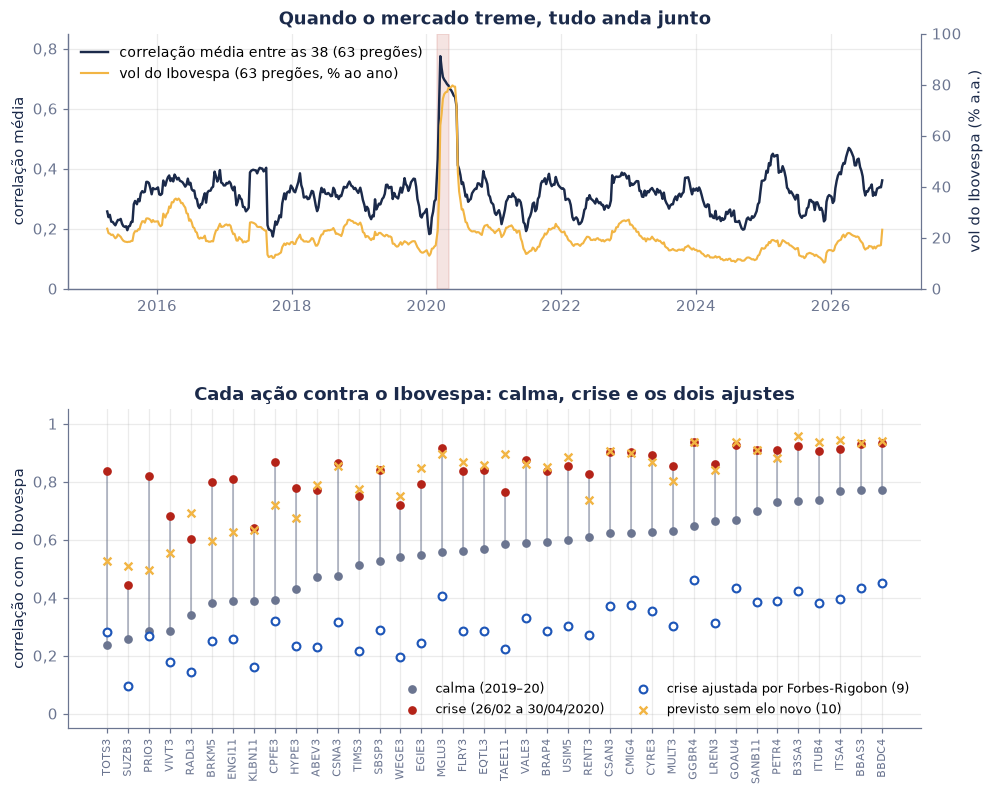

In [18]:
roll = []
for t in range(63, len(R38) + 1, 5):
    g = R38.iloc[t - 63:t]
    roll.append((g.index[-1], np.nanmean(g.corr(min_periods=40).values[iu]), mkt.iloc[t - 63:t].std() * v))   # sem os trechos vazios
roll = pd.DataFrame(roll, columns=["data", "corr", "vol"]).set_index("data")
print(f"correlação média de 63 dias: de {br(roll['corr'].min())} ({roll['corr'].idxmin():%d/%m/%Y}) a {br(roll['corr'].max())} ({roll['corr'].idxmax():%d/%m/%Y}); "
      f"correlação dela com a vol do Ibovespa: {br(roll['corr'].corr(roll['vol']))}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8.2), gridspec_kw={"height_ratios": [1, 1.25], "hspace": 0.42})
ax1.plot(roll.index, roll["corr"], color=NAVY, lw=1.6, label="correlação média entre as 38 (63 pregões)")
ax1.axvspan(pd.Timestamp(CRISE[0]), pd.Timestamp(CRISE[1]), color=RED, alpha=0.12)
ax1.set(ylabel="correlação média", ylim=(0, 0.85), title="Quando o mercado treme, tudo anda junto")
axb = ax1.twinx(); axb.plot(roll.index, 100 * roll["vol"], color=AMBER, lw=1.4, label="vol do Ibovespa (63 pregões, % ao ano)")
axb.set(ylabel="vol do Ibovespa (% a.a.)", ylim=(0, 100)); axb.spines["right"].set_visible(True); axb.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = axb.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", fontsize=9)
o = fr.sort_values("ρ calma"); xs = np.arange(nA)
ax2.vlines(xs, o["ρ calma"], o["ρ crise"], color=GREY, lw=1, alpha=0.6)
ax2.scatter(xs, o["ρ calma"], color=GREY, s=22, label="calma (2019–20)", zorder=3)
ax2.scatter(xs, o["ρ crise"], color=RED, s=22, label="crise (26/02 a 30/04/2020)", zorder=3)
ax2.scatter(xs, o["ρ* (9)"], facecolor="white", edgecolor=BLUE, s=26, lw=1.4, label="crise ajustada por Forbes-Rigobon (9)", zorder=3)
ax2.scatter(xs, o["ρ previsto (10)"], marker="x", color=AMBER, s=26, lw=1.6, label="previsto sem elo novo (10)", zorder=4)
ax2.set_xticks(xs); ax2.set_xticklabels(o.index, rotation=90, fontsize=7)
ax2.set(ylabel="correlação com o Ibovespa", ylim=(-0.05, 1.05), title="Cada ação contra o Ibovespa: calma, crise e os dois ajustes")
virgula(ax1, x=False); virgula(ax2, x=False); ax2.legend(frameon=False, ncol=2, fontsize=8.5, loc="lower right"); plt.show()

**Leitura.** O "tudo cai junto" de 2020 é real: a correlação das ações com o Ibovespa foi de 0,55 para 0,83 e subiu em todas as 38; entre pares de ações, de 0,31 para 0,69. O intervalo de 95 % em blocos para o aumento médio, de +0,15 a +0,37, passa longe de zero. Um teste ingênuo diria: contágio.

Com o ajuste de Forbes e Rigobon, eq. (9), o aumento não só some como **vira queda**: a correlação ajustada da crise, 0,30, fica abaixo da calma em 37 das 38 ações, e o intervalo da diferença (−0,28 a −0,17) é todo negativo. Isso não é "anticontágio". É uma hipótese do ajuste que falha: ele supõe que o risco próprio das empresas não muda, e em 2020 a variância do resíduo ficou 4,9 vezes maior (mediana das 38), enquanto a do Ibovespa ficou 26,8 vezes. Com os dois na conta, eq. (10), a correlação prevista **sem elo novo nenhum** é 0,80, contra 0,83 observada; a diferença, +0,03, tem intervalo em blocos de −0,01 a +0,06, que inclui o zero. Os betas mal mudaram (0,90 para 0,97), e a correlação média dos resíduos entre pares ficou em +0,01 na calma e na crise. Entre pares, o mercado mais volátil sozinho levaria a correlação média a 0,89; com o risco próprio da crise, a 0,64; a observada foi 0,69. Só com março de 2020, a mesma história: 0,86 observada, 0,83 pela eq. (10), 0,27 pelo ajuste (9).

A conclusão de Forbes e Rigobon sobrevive, com um asterisco: em 2020, na B3, não há sinal de contágio, só interdependência; mas a correção deles, sozinha, passa do ponto, porque na crise o risco de cada empresa também cresce. É a crítica de Corsetti, Pericoli e Sbracia (2005): com o risco próprio variando, o teste de Forbes e Rigobon pende para "sem contágio". Para quem tem a carteira, a mecânica não consola: a correlação **medida** subiu, e a diversificação entregou menos justamente quando era mais necessária.

## 11. Mesa: hedge de variância mínima — eq. (11)

Um operador está comprado em **R\$ 1 milhão de Itaú** (ITUB4) e quer tirar o risco do setor ou da bolsa sem vender as ações. Vende $h$ reais de outro ativo B para cada real de Itaú. A variância da posição, $\sigma_A^2 - 2h\rho\sigma_A\sigma_B + h^2\sigma_B^2$, é mínima em

$$
h^{*} = \rho\,\frac{\sigma_A}{\sigma_B}, \qquad \sigma^2_{A - h^{*}B} = \sigma_A^2\,\big(1-\rho^2\big) \tag{11}
$$

O hedge tira $\rho^2$ da variância, mas só $1-\sqrt{1-\rho^2}$ do desvio-padrão. Dois candidatos para B: o concorrente (Bradesco, BBDC4) e a bolsa (BOVA11, o ETF do Ibovespa). Primeiro com a amostra toda; depois **fora da amostra**: a cada 21 pregões, o $h^*$ é estimado com os 252 pregões anteriores e usado nos 21 seguintes.

In [19]:
posicao = 1_000_000
linhas = []
for hb in ("BBDC4", "BOVA11", "IBOV"):
    rho_ = RP["ITUB4"].corr(RP[hb]); h_ = rho_ * RP["ITUB4"].std() / RP[hb].std()
    linhas.append({"hedge": NOMES[hb], "ρ": rho_, "h* (11)": h_, "vender (R$)": h_ * posicao, "variância tirada (ρ²)": rho_ ** 2, "desvio tirado": 1 - math.sqrt(1 - rho_ ** 2)})
dentro = pd.DataFrame(linhas).set_index("hedge")
display(dentro.style.format({"ρ": F(br, 3), "h* (11)": F(br, 3), "vender (R$)": F(br, 0), "variância tirada (ρ²)": F(pct), "desvio tirado": F(pct)})
        .set_caption(f"R$ 1 milhão em ITUB4, amostra inteira ({RP.index[0]:%Y}–{RP.index[-1]:%Y})"))

def hedge_fora(hb, janela=252, passo=21):
    pl_sem, pl_com, hs = [], [], []
    for t0 in range(janela, len(RP), passo):
        est, prox = RP.iloc[t0 - janela:t0], RP.iloc[t0:t0 + passo]
        h_ = est["ITUB4"].cov(est[hb]) / est[hb].var(); hs.append(h_)
        pl_sem.append(posicao * prox["ITUB4"]); pl_com.append(posicao * (prox["ITUB4"] - h_ * prox[hb]))
    return pd.concat(pl_sem), pd.concat(pl_com), np.array(hs)

fora = {}
for hb in ("BBDC4", "BOVA11"):
    pl_sem, pl_com, hs = hedge_fora(hb); fora[hb] = pl_com
    print(f"{NOMES[hb]:>8}: h* de {br(hs.min())} a {br(hs.max())}; desvio diário R$ {br(pl_sem.std(), 0)} → R$ {br(pl_com.std(), 0)}; variância tirada {pct(1 - pl_com.var() / pl_sem.var())}; "
          f"VaR 95 % de 1 dia (normal) {brl(1.645 * pl_sem.std())} → {brl(1.645 * pl_com.std())}; pior 5 % histórico {brl(-np.percentile(pl_sem, 5))} → {brl(-np.percentile(pl_com, 5))}")
fora["sem hedge"] = pl_sem
print(f"fora da amostra: {pl_sem.index[0]:%d/%m/%Y} a {pl_sem.index[-1]:%d/%m/%Y}, {len(pl_sem)} pregões")
porano_h = pd.DataFrame({hb: [1 - fora[hb][fora[hb].index.year == y].var() / pl_sem[pl_sem.index.year == y].var() for y in sorted(set(pl_sem.index.year))] for hb in ("BBDC4", "BOVA11")},
                        index=sorted(set(pl_sem.index.year)))
print("variância tirada, fora da amostra, por ano:", "; ".join(f"{y}: Bradesco {pct(r_['BBDC4'], 0)}, BOVA11 {pct(r_['BOVA11'], 0)}" for y, r_ in porano_h.iterrows()))
print(f"para o hedge tirar 90 % do desvio, a correlação precisaria ser √(1 − 0,1²) = {br(math.sqrt(1 - 0.1 ** 2), 3)}")
nivel = ibov.iloc[-1]; h_ib = dentro.loc["Ibovespa", "h* (11)"]
print(f"\ncom mini-índice (R$ 0,20 por ponto, Ibovespa a {br(nivel, 0)} pontos em {ibov.index[-1]:%d/%m/%Y}): vender {br(h_ib * posicao / (0.2 * nivel), 1)} contratos")

,ρ,h* (11),vender (R$),variância tirada (ρ²),desvio tirado
hedge,,,,,
Bradesco,"0,829","0,721",721.069,"68,7 %","44,1 %"
BOVA11,"0,783","1,001",1.000.819,"61,3 %","37,8 %"
Ibovespa,"0,799","1,038",1.038.075,"63,8 %","39,8 %"


Bradesco: h* de 0,34 a 0,88; desvio diário R$ 18.793 → R$ 10.517; variância tirada 68,7 %; VaR 95 % de 1 dia (normal) R$ 30.914 → R$ 17.301; pior 5 % histórico R$ 26.950 → R$ 14.142


  BOVA11: h* de 0,77 a 1,27; desvio diário R$ 18.793 → R$ 11.890; variância tirada 60,0 %; VaR 95 % de 1 dia (normal) R$ 30.914 → R$ 19.560; pior 5 % histórico R$ 26.950 → R$ 17.234
fora da amostra: 13/01/2016 a 16/10/2026, 2672 pregões
variância tirada, fora da amostra, por ano: 2016: Bradesco 72 %, BOVA11 64 %; 2017: Bradesco 76 %, BOVA11 69 %; 2018: Bradesco 79 %, BOVA11 72 %; 2019: Bradesco 67 %, BOVA11 52 %; 2020: Bradesco 86 %, BOVA11 67 %; 2021: Bradesco 62 %, BOVA11 45 %; 2022: Bradesco 55 %, BOVA11 41 %; 2023: Bradesco 59 %, BOVA11 55 %; 2024: Bradesco 15 %, BOVA11 43 %; 2025: Bradesco 32 %, BOVA11 60 %; 2026: Bradesco 67 %, BOVA11 72 %
para o hedge tirar 90 % do desvio, a correlação precisaria ser √(1 − 0,1²) = 0,995

com mini-índice (R$ 0,20 por ponto, Ibovespa a 205.430 pontos em 16/10/2026): vender 25,3 contratos


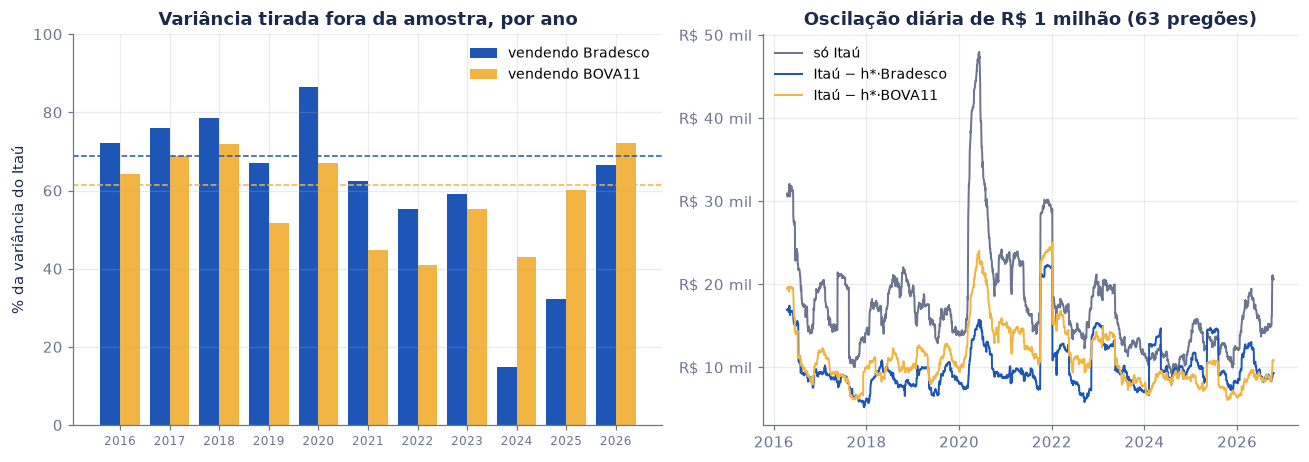

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
anos_ = porano_h.index.values
ax1.bar(anos_ - 0.2, 100 * porano_h["BBDC4"], 0.4, color=BLUE, label="vendendo Bradesco")
ax1.bar(anos_ + 0.2, 100 * porano_h["BOVA11"], 0.4, color=AMBER, label="vendendo BOVA11")
ax1.axhline(100 * dentro.loc["Bradesco", "variância tirada (ρ²)"], color=BLUE, ls="--", lw=1)
ax1.axhline(100 * dentro.loc["BOVA11", "variância tirada (ρ²)"], color=AMBER, ls="--", lw=1)
ax1.set(title="Variância tirada fora da amostra, por ano", ylabel="% da variância do Itaú", ylim=(0, 100), xticks=anos_)
ax1.tick_params(axis="x", labelsize=8); ax1.legend(frameon=False, loc="upper right", fontsize=9)
for nome, cor in (("sem hedge", GREY), ("BBDC4", BLUE), ("BOVA11", AMBER)):
    ax2.plot(fora[nome].rolling(63).std(), color=cor, lw=1.3, label={"sem hedge": "só Itaú", "BBDC4": "Itaú − h*·Bradesco", "BOVA11": "Itaú − h*·BOVA11"}[nome])
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y_, _: "R$ " + br(y_ / 1000, 0) + " mil"))
ax2.set(title="Oscilação diária de R$ 1 milhão (63 pregões)"); ax2.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

**Leitura.** Correlação de 0,83 parece quase 1, mas o hedge com Bradesco tira 69 % da variância e só 44 % do desvio: o VaR diário de R\$ 1 milhão cai de uns R\$ 31 mil para uns R\$ 17 mil. Para tirar 90 % do desvio, a correlação precisaria ser 0,995. Fora da amostra, o Bradesco entrega o prometido na média de dez anos, mas falha justamente quando o vizinho tem problema próprio: em 2024, quando a correlação dos dois caiu para 0,53, o hedge com Bradesco tirou só 15 % da variância, e o com BOVA11, 43 %. O concorrente protege melhor contra o setor; o índice, contra as surpresas do concorrente. Na mesa, escolher o hedge é escolher qual correlação vai continuar valendo.

## 12. Investidor: meio Ibovespa, meio dólar

Para quem investe em reais, o dólar é o par mais negativo que existe à mão: a correlação diária com o Ibovespa foi negativa em todos os anos desde 2000. Uma carteira meio a meio (rebalanceada todo dia, para seguir a eq. (7)) contra cada um sozinho, ano a ano. O dólar aqui é a variação da PTAX, sem juros: um fundo cambial ou um ETF de dólar tem custo e o diferencial de juros.

In [21]:
Q = pd.concat([ibov.rename("IBOV"), ptax.rename("DOLAR")], axis=1, join="inner")
RQ = Q.pct_change().iloc[1:]; RQ["MISTURA"] = RQ[["IBOV", "DOLAR"]].mean(axis=1)
W = Q.resample("W-FRI").last().pct_change().iloc[1:]
g = RQ.groupby(RQ.index.year)
inv = pd.DataFrame({"ρ diário": g.apply(lambda d: d["IBOV"].corr(d["DOLAR"])), "ρ semanal": W.groupby(W.index.year).apply(lambda d: d["IBOV"].corr(d["DOLAR"])),
                    "σ Ibovespa": g["IBOV"].std() * v, "σ dólar": g["DOLAR"].std() * v, "σ 50/50": g["MISTURA"].std() * v})
inv["média dos dois σ"] = (inv["σ Ibovespa"] + inv["σ dólar"]) / 2
fim = Q.groupby(Q.index.year).last(); base = pd.concat([Q.iloc[[0]].set_axis([Q.index[0].year - 1]), fim])
ret = (base / base.shift(1) - 1).iloc[1:]; ret["50/50"] = ret.mean(axis=1)
inv["retorno Ibovespa"], inv["retorno dólar"], inv["retorno 50/50"] = ret["IBOV"], ret["DOLAR"], ret["50/50"]
inv.index.name = "ano"
display(inv.style.format({c_: (F(sg) if c_.startswith("ρ") else F(spct) if c_.startswith("retorno") else F(pct)) for c_ in inv.columns})
        .set_caption(f"Ibovespa e dólar PTAX, {Q.index[0]:%d/%m/%Y} a {Q.index[-1]:%d/%m/%Y} (1999 começa em 04/01; 2026 vai até 16/10)"))
print(f"anos em que o 50/50 oscilou menos que a média dos dois: {(inv['σ 50/50'] < inv['média dos dois σ']).sum()} de {len(inv)}; "
      f"anos de correlação diária negativa: {(inv['ρ diário'] < 0).sum()} de {len(inv)}")
d99 = RQ.loc["1999", "IBOV"].idxmax()
print(f"o maior dia de 1999: {d99:%d/%m/%Y}, Ibovespa {spct(RQ.loc[d99, 'IBOV'])} e dólar {spct(RQ.loc[d99, 'DOLAR'])} no mesmo dia")

,ρ diário,ρ semanal,σ Ibovespa,σ dólar,σ 50/50,média dos dois σ,retorno Ibovespa,retorno dólar,retorno 50/50
ano,,,,,,,,,
1999,"+0,21","+0,00","49,8 %","27,8 %","30,9 %","38,8 %","+146,2 %","+48,1 %","+97,2 %"
2000,"−0,32","−0,52","32,9 %","8,1 %","15,6 %","20,5 %","−10,7 %","+9,3 %","−0,7 %"
2001,"−0,29","−0,53","33,3 %","16,4 %","16,2 %","24,8 %","−11,0 %","+18,7 %","+3,8 %"
2002,"−0,22","−0,68","32,9 %","24,7 %","18,3 %","28,8 %","−17,0 %","+52,3 %","+17,6 %"
2003,"−0,38","−0,64","24,2 %","13,6 %","11,4 %","18,9 %","+97,3 %","−18,2 %","+39,6 %"
2004,"−0,47","−0,70","28,5 %","9,1 %","12,8 %","18,8 %","+17,8 %","−8,1 %","+4,8 %"
2005,"−0,24","−0,32","24,9 %","12,7 %","12,6 %","18,8 %","+27,7 %","−11,8 %","+7,9 %"
2006,"−0,47","−0,63","24,2 %","13,2 %","10,7 %","18,7 %","+32,9 %","−8,7 %","+12,1 %"
2007,"−0,54","−0,73","27,4 %","13,1 %","11,5 %","20,3 %","+43,6 %","−17,2 %","+13,2 %"


anos em que o 50/50 oscilou menos que a média dos dois: 28 de 28; anos de correlação diária negativa: 27 de 28
o maior dia de 1999: 15/01/1999, Ibovespa +33,4 % e dólar +11,1 % no mesmo dia


In [22]:
M_ = Q.resample("ME").last().pct_change().iloc[1:]
freq = pd.DataFrame({"diário": [RQ["IBOV"].corr(RQ["DOLAR"]), RQ["IBOV"].std() * v, RQ["DOLAR"].std() * v, RQ["MISTURA"].std() * v],
                     "semanal": [W["IBOV"].corr(W["DOLAR"]), W["IBOV"].std() * math.sqrt(52), W["DOLAR"].std() * math.sqrt(52), W.mean(axis=1).std() * math.sqrt(52)],
                     "mensal": [M_["IBOV"].corr(M_["DOLAR"]), M_["IBOV"].std() * math.sqrt(12), M_["DOLAR"].std() * math.sqrt(12), M_.mean(axis=1).std() * math.sqrt(12)]},
                    index=["ρ", "σ Ibovespa (a.a.)", "σ dólar (a.a.)", "σ 50/50 (a.a.)"])
display(freq.style.format(F(pct)).format(F(sg, 3), subset=pd.IndexSlice[["ρ"], :]).set_caption(f"a mesma amostra em três frequências ({Q.index[0]:%Y}–{Q.index[-1]:%Y})"))
cruz = {k_: RQ["IBOV"].corr(RQ["DOLAR"].shift(-k_)) for k_ in (-1, 0, 1)}
print(f"correlação do Ibovespa de hoje com a PTAX de ontem {sg(cruz[-1], 3)}, de hoje {sg(cruz[0], 3)}, de amanhã {sg(cruz[1], 3)}; soma {sg(sum(cruz.values()), 3)}")
print(f"defasagem implícita da PTAX (fração do dia, nota técnica): θ = {br(cruz[1] / (cruz[0] + cruz[1]), 2)}")
for nome_, (s1, s2, r12) in {"diário": (RQ["IBOV"].std() * v, RQ["DOLAR"].std() * v, cruz[0]), "semanal": tuple(freq.loc[["σ Ibovespa (a.a.)", "σ dólar (a.a.)", "ρ"], "semanal"])}.items():
    w_ = (s2 ** 2 - r12 * s1 * s2) / (s1 ** 2 + s2 ** 2 - 2 * r12 * s1 * s2)            # peso do Ibovespa na mistura de menor risco
    s_ = math.sqrt(w_ ** 2 * s1 ** 2 + (1 - w_) ** 2 * s2 ** 2 + 2 * w_ * (1 - w_) * r12 * s1 * s2)
    print(f"mistura de menor risco ({nome_}): {pct(w_, 0)} em Ibovespa, σ = {pct(s_)}  |  50/50: σ = {pct(math.sqrt(0.25 * s1 ** 2 + 0.25 * s2 ** 2 + 0.5 * r12 * s1 * s2))}")

,diário,semanal,mensal
ρ,"−0,302","−0,509","−0,638"
σ Ibovespa (a.a.),"28,0 %","25,9 %","24,3 %"
σ dólar (a.a.),"15,6 %","16,3 %","16,9 %"
σ 50/50 (a.a.),"13,8 %","11,2 %","9,4 %"


correlação do Ibovespa de hoje com a PTAX de ontem +0,015, de hoje −0,302, de amanhã −0,210; soma −0,496
defasagem implícita da PTAX (fração do dia, nota técnica): θ = 0,41
mistura de menor risco (diário): 29 % em Ibovespa, σ = 11,6 %  |  50/50: σ = 13,8 %
mistura de menor risco (semanal): 35 % em Ibovespa, σ = 9,8 %  |  50/50: σ = 11,2 %


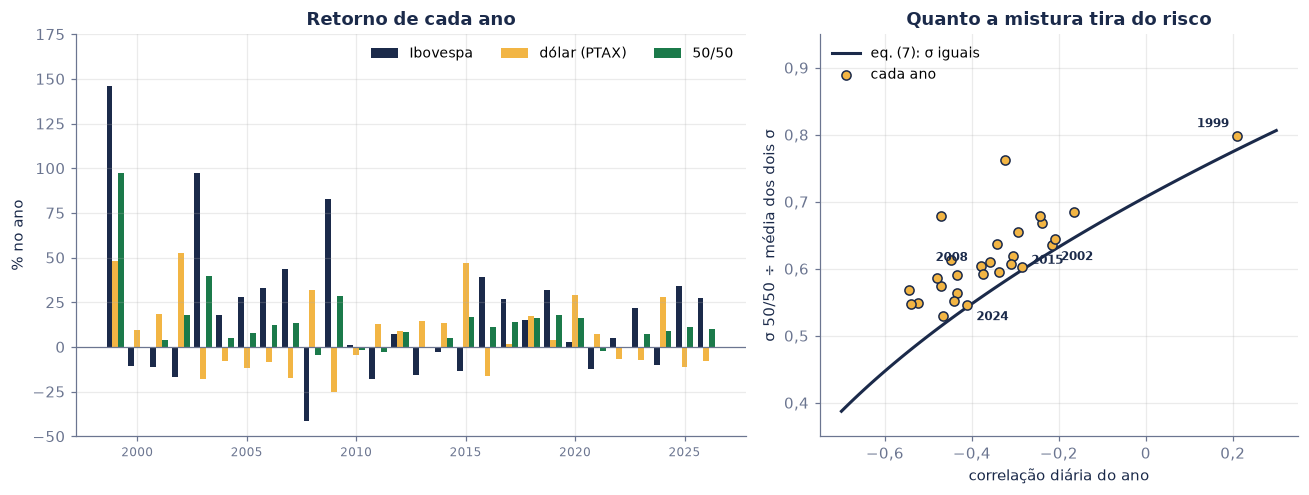

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
yy = inv.index.values
ax1.bar(yy - 0.27, 100 * inv["retorno Ibovespa"], 0.27, color=NAVY, label="Ibovespa")
ax1.bar(yy, 100 * inv["retorno dólar"], 0.27, color=AMBER, label="dólar (PTAX)")
ax1.bar(yy + 0.27, 100 * inv["retorno 50/50"], 0.27, color=GREEN, label="50/50")
ax1.axhline(0, color=GREY, lw=0.8); ax1.set(title="Retorno de cada ano", ylabel="% no ano", ylim=(-50, 175)); ax1.legend(frameon=False, ncol=3, fontsize=9, loc="upper right")
ax1.tick_params(axis="x", labelsize=8)
rr_ = np.linspace(-0.7, 0.3, 100); ax2.plot(rr_, np.sqrt((1 + rr_) / 2), color=NAVY, lw=2, label="eq. (7): σ iguais")
razao = inv["σ 50/50"] / inv["média dos dois σ"]
ax2.scatter(inv["ρ diário"], razao, color=AMBER, edgecolor=NAVY, s=36, zorder=3, label="cada ano")
for y_, (dx, dy) in {1999: (-26, 6), 2002: (6, -10), 2008: (-14, 9), 2015: (6, 2), 2024: (6, -10)}.items():
    ax2.annotate(str(y_), (inv.loc[y_, "ρ diário"], razao.loc[y_]), (dx, dy), textcoords="offset points", fontsize=8, color=NAVY, weight="bold")
ax2.set(xlabel="correlação diária do ano", ylabel="σ 50/50 ÷ média dos dois σ", title="Quanto a mistura tira do risco", ylim=(0.35, 0.95))
virgula(ax2); ax2.legend(frameon=False, fontsize=9, loc="upper left"); plt.tight_layout(); plt.show()

**Leitura.** Em todos os 28 anos, a mistura oscilou menos que a média dos dois. Em 2002, 2008 e 2015, anos ruins para a bolsa, o dólar subiu forte e segurou a carteira (−17 % na bolsa e +52 % no dólar em 2002; −41 % e +32 % em 2008; −13 % e +47 % em 2015). Em 2020, o ano do tombo de março, a bolsa terminou em +2,9 % e o dólar em +28,9 %. A exceção que confirma: 1999, ano da desvalorização, com correlação **positiva**, porque no dia em que o câmbio foi solto, 15/01/1999, a bolsa subiu 33,4 % e o dólar, 11,1 %. Os pontos ficam acima da curva da eq. (7) porque o Ibovespa oscila quase o dobro do dólar. Com riscos desiguais, a mistura meio a meio não é a de menor risco: a de menor risco tem 29 % de Ibovespa e oscila 11,6 % ao ano, contra 13,8 % da meio a meio (no semanal, 35 % e 9,8 %).

Um detalhe de horário muda o número. A PTAX é a média de quatro consultas entre 10h e 13h; o Ibovespa fecha às 17h. O que a bolsa faz de tarde só aparece na PTAX do dia seguinte: a correlação com a PTAX de amanhã é −0,21. Somando os dias vizinhos, a correlação diária vai de −0,30 para perto de −0,50, quase a semanal (−0,51); a mensal é −0,64. Medida no diário, a proteção do dólar parece menor do que é.

## 13. O que a correlação não vê

1. **Só o que é linear, e só na média.** $y = x^2$ tem correlação zero; poucos dias de pânico fazem uma correlação alta (seção 6). Dois pares com o mesmo $\rho$ podem ter caudas completamente diferentes; Longin e Solnik (2001) mostram que a correlação entre bolsas é maior nas quedas que nas altas.
2. **Ela muda.** Itaú e Bradesco foram de 0,93 a 0,53 em quatro anos (seção 7). Uma correlação estimada é uma média do passado, não uma constante da natureza, e o erro dela chega a 3,4 vezes o de Fisher (seção 8).
3. **Não é causa, e na crise sobe por mecânica.** O mercado escondido move os dois ativos (seção 3); quando ele fica mais volátil, a correlação sobe sem elo novo nenhum (seção 10). Correlação alta na crise não prova contágio; correlação baixa na calma não promete proteção.
4. **Depende do relógio.** Preços medidos em horários diferentes (PTAX às 13h, bolsa às 17h) ou ativos pouco negociados derrubam a correlação diária; a semanal corrige boa parte (seção 12, efeito de Epps).
5. **Não diz nada sobre retorno.** O dólar protege a carteira em reais, mas no longo prazo rende menos que a bolsa. A correlação decide o risco da mistura; o quanto pôr em cada um depende também do que se espera ganhar.

### Para praticar (respostas na célula seguinte)

1. Dois ativos oscilam 30 % e 10 % ao ano, com correlação −0,20. Qual o risco da carteira meio a meio? E o da média dos dois riscos?
2. Com 38 ações de 35 % ao ano e correlação média 0,35, qual o piso de risco de uma carteira de pesos iguais? E com 10 ações?
3. Uma correlação de 0,60 foi medida com 100 dias. Qual o intervalo de 95 % de Fisher? Se os dados fossem diários, você confiaria nele?
4. Na calma, uma ação tem correlação 0,50 com o índice. Na crise, a variância do índice quadruplica e o risco próprio fica igual. Qual a correlação esperada na crise? E se o risco próprio dobrar?
5. Hedge: $\rho = 0{,}9$, $\sigma_A = 30\,\%$, $\sigma_B = 25\,\%$. Qual o $h^*$, quanto vender para R\$ 500 mil de A, e qual o risco que sobra?

In [24]:
print("1)", f"√(0,25·0,09 + 0,25·0,01 + 2·0,25·(−0,2)·0,3·0,1) = {pct(math.sqrt(0.25 * 0.09 + 0.25 * 0.01 + 2 * 0.25 * -0.2 * 0.03))}; média dos riscos 20,0 %")
print("2)", f"piso 35 % × √0,35 = {pct(0.35 * math.sqrt(0.35))}; com 10 ações, 35 % × √(0,1 + 0,9·0,35) = {pct(0.35 * math.sqrt(0.1 + 0.9 * 0.35))}")
lo3, hi3 = np.tanh(np.arctanh(0.6) + np.array([-1.96, 1.96]) / math.sqrt(97))
print("3)", f"atanh 0,6 = {br(np.arctanh(0.6), 4)} ± 1,96/√97 -> de {br(lo3)} a {br(hi3)}; com dado diário, não: nos pares da seção 8, o erro em blocos foi 1,7 a 3,4 vezes o de Fisher")
r4 = lambda rc_, d_, g_: math.sqrt(rc_ ** 2 * (1 + d_) / (rc_ ** 2 * (1 + d_) + (1 - rc_ ** 2) * (1 + g_)))
print("4)", f"eq. (10) com δ = 3: γ = 0 dá {br(r4(0.5, 3, 0), 3)}; γ = 1 dá {br(r4(0.5, 3, 1), 3)}")
print("5)", f"h* = 0,9 × 30/25 = {br(0.9 * 30 / 25)}; vender {brl(0.9 * 30 / 25 * 500_000)}; sobra 30 % × √(1 − 0,81) = {pct(0.30 * math.sqrt(0.19))}: "
      f"tirou 81 % da variância e {pct(1 - math.sqrt(0.19), 0)} do desvio")

1) √(0,25·0,09 + 0,25·0,01 + 2·0,25·(−0,2)·0,3·0,1) = 14,8 %; média dos riscos 20,0 %
2) piso 35 % × √0,35 = 20,7 %; com 10 ações, 35 % × √(0,1 + 0,9·0,35) = 22,5 %
3) atanh 0,6 = 0,6931 ± 1,96/√97 -> de 0,46 a 0,71; com dado diário, não: nos pares da seção 8, o erro em blocos foi 1,7 a 3,4 vezes o de Fisher
4) eq. (10) com δ = 3: γ = 0 dá 0,756; γ = 1 dá 0,632
5) h* = 0,9 × 30/25 = 1,08; vender R$ 540.000; sobra 30 % × √(1 − 0,81) = 13,1 %: tirou 81 % da variância e 56 % do desvio


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Média dos produtos | $\rho = \frac{1}{n}\sum_t z_{A,t}\,z_{B,t}$ | +0,80; dia 1: +2,60; dia 146: −0,43 |
| (2) Definição de Pearson | $\rho = \mathrm{Cov}(A,B)/(\sigma_A\sigma_B)$ | igual à (1) até a 4ª casa |
| (3) Os limites | $\frac{1}{n}\sum(z_A \mp z_B)^2 = 2(1\mp\rho) \ge 0$ | sempre de −1 a +1 |
| (4) Um fator | $\rho_{AB} = \beta_A\beta_B\sigma_M^2/(\sigma_A\sigma_B)$ | o $c$ do programa; 97 % da correlação média da B3 |
| (5) Erro da média e da correlação | $\sqrt{(1+\rho^2)/n}$ e $(1-\rho^2)/\sqrt n$ | 0,081 e 0,023 em um ano |
| (6) Fisher | $\mathrm{atanh}\,\hat\rho \approx \mathcal N(\mathrm{atanh}\,\rho,\,1/(n-3))$ | certo na simulação; na B3, erro 1,7 a 3,4× menor que o dos blocos |
| (7) Mistura 50/50 | $\sigma\sqrt{(1+\rho)/2}$ | 19,0 %, 14,1 % e 10,0 % |
| (8) Caso geral e N ativos | $\sigma_p^2 = w^2\sigma_A^2 + \cdots$; piso $\sigma\sqrt{\bar\rho}$ | 50/50 Ibovespa + dólar |
| (9) Forbes-Rigobon | $\rho^* = \rho/\sqrt{1+\delta(1-\rho^2)}$ | 0,83 na crise → 0,30 |
| (10) Com risco próprio | $\rho_h^2 = \frac{\rho_l^2(1+\delta)}{\rho_l^2(1+\delta) + (1-\rho_l^2)(1+\gamma)}$ | previsto 0,80, observado 0,83 |
| (11) Hedge | $h^* = \rho\,\sigma_A/\sigma_B$; tira $\rho^2$ da variância | Itaú com Bradesco: 69 % |

### Referências

- Corsetti, G.; Pericoli, M.; Sbracia, M. (2005). Some contagion, some interdependence: more pitfalls in tests of financial contagion. *Journal of International Money and Finance*, 24(8).
- Dimson, E. (1979). Risk measurement when shares are subject to infrequent trading. *Journal of Financial Economics*, 7(2).
- Ederington, L. H. (1979). The hedging performance of the new futures markets. *Journal of Finance*, 34(1).
- Epps, T. W. (1979). Comovements in stock prices in the very short run. *Journal of the American Statistical Association*, 74(366).
- Fisher, R. A. (1915). Frequency distribution of the values of the correlation coefficient in samples from an indefinitely large population. *Biometrika*, 10(4).
- Forbes, K. J.; Rigobon, R. (2002). No contagion, only interdependence: measuring stock market comovements. *Journal of Finance*, 57(5).
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *Annals of Statistics*, 17(3).
- Longin, F.; Solnik, B. (2001). Extreme correlation of international equity markets. *Journal of Finance*, 56(2).
- Markowitz, H. (1952). Portfolio selection. *Journal of Finance*, 7(1).
- Pearson, K. (1895). Notes on regression and inheritance in the case of two parents. *Proceedings of the Royal Society of London*, 58.

*Gabriel Pires · [gabrielppires.com](https://gabrielppires.com) · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · O vídeo é inspirado em* Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Retornos simulados nas seções 0 a 6; dados reais do Yahoo Finance e do Banco Central nas seções 7 a 12. Só educação, não é recomendação de investimento.*